<a href="https://colab.research.google.com/github/rithakith/sri-lankan-news-ensemble/blob/main/News_Training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Automated News Classification Training

### Step 1.1 — Import the tools

In [ ]:
from pathlib import Path

import os, re, json, hashlib, unicodedata, time, platform, itertools, copy

import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

import joblib

import sklearn, xgboost

from IPython.display import display, Markdown

from sklearn.pipeline import Pipeline

from sklearn.feature_extraction.text import TfidfVectorizer, HashingVectorizer

from sklearn.linear_model import LogisticRegression

from sklearn.svm import LinearSVC

from sklearn.ensemble import RandomForestClassifier

from sklearn.preprocessing import LabelEncoder

from sklearn.model_selection import StratifiedGroupKFold

from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay)

from xgboost import XGBClassifier


### Step 1.2 — Import the preprocessed file

In [ ]:
from google.colab import drive

if not Path('/content/drive/MyDrive').exists():
    drive.mount('/content/drive')

SEED = 42

DATA_ROOT = Path('/content/drive/MyDrive/News_Preprocessing')

INPUT_CSV = DATA_ROOT / 'news_english_top_10000_final.csv'


### Step 1.3 — Set Up the Run Configuration, Hashes, and Output Folders


In [ ]:
DATA_HASH = hashlib.sha256(INPUT_CSV.read_bytes()).hexdigest()

OUT = DATA_ROOT / 'News_Assignment_Improved' / DATA_HASH[:12]

OUT.mkdir(parents=True, exist_ok=True)

FIG = OUT / 'figures'

FIG.mkdir(exist_ok=True)

CONFIG = dict(seed=SEED, duplicate_cosine=.90, audit_size=300, features=12000,
              rf_trees=100, xgb_trees=80, oof_folds=3, protocol='group_audit_v1')

RUN_HASH = hashlib.sha256((json.dumps(CONFIG,sort_keys=True)+DATA_HASH).encode()).hexdigest()

SECTIONS, FIGURES = {}, []


### Step 1.4 — Define prose

This reusable function is defined here; it runs only when called by a later step. Its inputs and returned values connect this step to the next operation.


In [ ]:
def prose(title, text):
    SECTIONS[title] = text
    display(Markdown('### '+title+'\n\n'+text))


### Step 1.5 — Define table

This reusable function is defined here; it runs only when called by a later step. Its inputs and returned values connect this step to the next operation.


In [ ]:
def table(name, frame):
    frame.to_csv(OUT / (name+'.csv'), index=False, encoding='utf-8-sig')
    display(frame)


### Step 1.6 — Define figure

This reusable function is defined here; it runs only when called by a later step. Its inputs and returned values connect this step to the next operation.


In [ ]:
def figure(name, interpretation):
    plt.tight_layout()
    plt.savefig(FIG/(name+'.png'), dpi=150, bbox_inches='tight')
    plt.show(); plt.close()
    FIGURES.append((name,interpretation))
    display(Markdown(interpretation))


### Step 1.7 — Display or export the result

Run this small step after the preceding step. Inspect any displayed table or message before continuing.


In [ ]:
print('Output:', OUT)

print('Runtime:',platform.python_version(), 'sklearn',sklearn.__version__,'XGBoost',xgboost.__version__)


Output: /content/drive/MyDrive/News_Preprocessing/News_Assignment_Improved/d18e3a420360
Runtime: 3.13.18 sklearn 1.6.1 XGBoost 3.4.1


## 2. Dataset loading and exploration


### Step 2.1 — Load the Input CSV and Check Required Columns

In [ ]:
raw = pd.read_csv(INPUT_CSV, dtype={'doc_id':str})

required = {'doc_id','description','text','predicted_topic','classification_score','score_margin'}

assert required <= set(raw), required-set(raw)


### Step 2.2 — Prepare TOPIC DEFINITIONS


In [ ]:
TOPIC_DEFINITIONS = {
 'politics_governance': 'Elections, parties, government, parliament, public policy and diplomacy.',
 'business_economy': 'Markets, prices, banking, company finances, employment, trade and public finance.',
 'crime_justice': 'Offences, arrests, investigations, legal disputes, trials and court orders.',
 'sport': 'Matches, athletes, teams, tournaments, selection and sporting administration.',
 'health_healthcare': 'Disease, medicine, treatment, hospitals, mental health and public health.',
 'weather_environment_disasters': 'Weather, climate, conservation, pollution, natural hazards and disaster relief.',
 'tourism_travel': 'Destinations, visitor experiences, hotels, travel advice and tourist entry arrangements.',
 'transport': 'Roads, railway, aviation, shipping, vehicles, passenger services and mobility.',
 'telecommunications': 'Mobile networks, broadband, connectivity, telecom services and network infrastructure.',
 'information_technology': 'Software, computing, AI, cybersecurity, digital systems and IT services.',
 'education': 'Schools, universities, students, examinations, teaching and learning.',
 'entertainment': 'Film, television, music, celebrities and performing arts.',
 'other': 'Readable lifestyle, culture, religion, general science and general-interest news outside the other categories.'}


### Step 2.3 — Validate Topic Labels, Set Up Label Encoding, and Summarize the Dataset

In [ ]:
TOPICS = sorted(TOPIC_DEFINITIONS)

assert set(raw.predicted_topic.dropna()) == set(TOPICS), 'Unexpected/missing category: inspect taxonomy'

encoder = LabelEncoder().fit(TOPICS)

K = len(TOPICS)

table('source_schema',pd.DataFrame({'column':raw.columns,'dtype':raw.dtypes.astype(str).values,'missing':raw.isna().sum().values}))

print('Loaded real articles:',len(raw))


,column,dtype,missing
0,doc_type,object,0
1,doc_id,object,0
2,num,object,0
3,date_str,object,0
4,description,object,0
5,url_metadata,object,0
6,lang,object,0
7,newspaper_id,object,0
8,time_ut,float64,0
9,text,object,0


Loaded real articles: 10000


## 3. Data cleaning and duplicate detection

### Step 3.1 — Define normalize function


In [ ]:
def normalize(text):
    return re.sub(r'\s+',' ',unicodedata.normalize('NFKC',str(text)).casefold()).strip()


### Step 3.2 — Define digest function


In [ ]:
def digest(text): return hashlib.sha256(text.encode()).hexdigest()


### Step 3.3 — Clean Article Records and Resolve Duplicate Document IDs

In [ ]:
df = raw.copy()

for c in ['description','text']: df[c]=df[c].fillna('').astype(str)

invalid = df.doc_id.isna() | df.predicted_topic.isna() | df.text.str.strip().eq('')

table('quarantined_rows',df.loc[invalid,['doc_id','description','predicted_topic']])

df = df.loc[~invalid].copy()

df['body_normalized']=df.text.map(normalize)

df['article']=df.description.str.strip()+'\n'+df.text.str.strip()

df['exact_hash']=df.article.map(normalize).map(digest)

for _,g in df.groupby('doc_id'):
    assert g.exact_hash.nunique()==1, 'Conflicting content under the same doc_id'

df = df.drop_duplicates('doc_id').sort_values('doc_id').reset_index(drop=True)


,doc_id,description,predicted_topic


### Step 3.4 — Validate Classification Scores and Identify Seed Articles

- Validate that both scores are numeric and within [0, 1].
- Mark articles as seed-eligible when the score is ≥ 0.70 and the margin is ≥ 0.20.
- Check that `needs_review` agrees with eligibility, if present.
- Start each article in its own group.

In [ ]:
for c in ['classification_score','score_margin']:
    df[c]=pd.to_numeric(df[c],errors='raise')
    assert np.isfinite(df[c]).all() and df[c].between(0,1).all()

df['seed_eligible']=df.classification_score.ge(.70)&df.score_margin.ge(.20)

if 'needs_review' in df:
    flags=df.needs_review.astype(str).str.strip().str.lower()
    assert flags.isin(['true','false']).all()
    assert df.seed_eligible.eq(flags.eq('false')).all()

parent=np.arange(len(df))


### Step 3.5 — Define root function

In [ ]:
def root(i):
    while parent[i]!=i:
        parent[i]=parent[parent[i]]; i=parent[i]
    return i


### Step 3.6 — Define union function


In [ ]:
def union(i,j):
    a,b=root(int(i)),root(int(j))
    if a!=b: parent[max(a,b)]=min(a,b)


### Step 3.7 — Group Exact Duplicates and Prepare for Near-Duplicate Detection

In [ ]:
edges=[]

for values in [df.exact_hash,df.body_normalized.map(digest)]:
    first={}
    for i,v in enumerate(values):
        if v in first: union(i,first[v])
        else: first[v]=i

hash_vectorizer=HashingVectorizer(n_features=2**20,ngram_range=(3,3),alternate_sign=False,
    binary=True,norm='l2',dtype=np.float32)

D=hash_vectorizer.transform(df.body_normalized)


### Step 3.8 — Detect and Group Near-Duplicate Articles

- Compare article bodies in batches of 128 using **cosine similarity**.
- Keep each pair once if its similarity is at least **0.90**, and skip self-comparisons.
- Merge matching articles into shared groups and assign each article a `duplicate_group` ID.
- Display matching pairs, their similarity scores, and the number of articles in each group.

Suppose two news websites publish nearly identical versions of the same story. Each version has a different doc_id.
- If you split by article ID, one version could go into the training set and the other into the test set. The model has already learned from nearly the same wording, so it may classify the test version correctly more easily. That can inflate the test score. This is called data leakage.
- If you split by duplicate_group, both versions go into the same partition. The test score then better reflects how well the model classifies articles whose wording it hasn’t already encountered in training.

In [ ]:
for start in range(0,len(df),128):
    similarity=(D[start:start+128]@D.T).tocoo()
    keep=(similarity.data>=CONFIG['duplicate_cosine']) & (similarity.row+start<similarity.col)
    for i,j,s in zip(similarity.row[keep]+start,similarity.col[keep],similarity.data[keep]):
        union(i,j);edges.append((df.doc_id.iloc[i],df.doc_id.iloc[j],float(s)))
    if start%2048==0: print('Duplicate scan:',start,'/',len(df),flush=True)

df['duplicate_group']=[df.doc_id.iloc[root(i)] for i in range(len(df))]

table('near_duplicate_edges',pd.DataFrame(edges,columns=['doc_id_a','doc_id_b','cosine']))

table('duplicate_group_sizes',df.groupby('duplicate_group').size().rename('articles').reset_index())

print('Unique IDs:',len(df),'content groups:',df.duplicate_group.nunique())

del D


Duplicate scan: 0 / 10000
Duplicate scan: 2048 / 10000
Duplicate scan: 4096 / 10000
Duplicate scan: 6144 / 10000
Duplicate scan: 8192 / 10000


,doc_id_a,doc_id_b,cosine
0,2024-01-07-colombotelegraphcom-640f5298,2024-01-07-dailyftlk-67651478,0.984773
1,2024-01-10-dailyftlk-b583e99f,2024-01-15-islandlk-a657751b,0.959887
2,2024-01-11-dailymirrorlk-8221fa08,2024-01-12-dailyftlk-d78c6381,0.966127
3,2024-01-12-dailyftlk-4fb7f454,2024-01-18-dailyftlk-4fb7f454,0.992602
4,2024-01-12-dailyftlk-dbcbe20e,2024-01-14-dbsjeyarajcom-9a3477e5,0.933217
...,...,...,...
383,2024-04-30-adaderanalk-10fc7888,2024-04-30-adaderanalk-4d88e7fb,0.974007
384,2024-04-30-dailymirrorlk-4e42969c,2024-04-30-dailymirrorlk-8e17645d,0.993441
385,2024-04-30-economynextcom-2d372b88,2024-04-30-economynextcom-368677b3,0.972829
386,2024-05-01-adaderanalk-5b8a1679,2024-05-01-adaderanalk-74b20e4c,0.941176


,duplicate_group,articles
0,2022-07-12-newsfirstlk-c83f4c6f,1
1,2023-10-07-newsfirstlk-ddd24a07,1
2,2023-10-18-dbsjeyarajcom-3a451bcb,1
3,2023-10-18-dbsjeyarajcom-d4bba182,1
4,2023-10-19-dbsjeyarajcom-15c6a51b,1
...,...,...
9623,2024-05-06-dailymirrorlk-3ad28d9c,1
9624,2024-05-06-dailymirrorlk-3fbbb81c,1
9625,2024-05-06-dailymirrorlk-4af2bc9d,1
9626,2024-05-06-dailymirrorlk-5633a584,1


Unique IDs: 10000 content groups: 9628


In [ ]:
group_sizes = df.groupby('duplicate_group').size()
group_sizes[group_sizes > 1].sum()

np.int64(727)

## 4. Independent human audit sampling

### Step 4.1 — Allocate 300 Audit Slots Using Stratified Sampling

- Keep one representative article per duplicate group.
- Form strata by predicted topic and seed eligibility.
- Allocate slots one at a time across strata in round-robin order, respecting each stratum’s capacity, until all 300 slots are assigned.

In [ ]:
representatives=df.drop_duplicates('duplicate_group').copy()

representatives['audit_stratum']=representatives.predicted_topic+'|'+representatives.seed_eligible.astype(str)

strata={s:g for s,g in representatives.groupby('audit_stratum',sort=True)}

capacity={s:max(0,len(g)-(min(5,len(g)-1) if g.seed_eligible.iloc[0] else min(2,len(g)-1))) for s,g in strata.items()}

allocation={s:0 for s in strata}

assert sum(capacity.values())>=300

while sum(allocation.values())<300:
    for s in allocation:
        if allocation[s]<capacity[s]: allocation[s]+=1
        if sum(allocation.values())==300: break

sample_parts=[]


### Step 4.2 — Draw a Stratified Random Sample of 300 Articles and Reserve Their Duplicate Groups for Audit

In [ ]:
for s,g in strata.items():
    n=allocation[s]
    if n:
        part=g.sample(n=n,random_state=SEED).copy()
        part['inclusion_probability']=n/len(g)
        part['sampling_weight']=len(g)/n
        part['audit_stratum']=s
        sample_parts.append(part)

audit=pd.concat(sample_parts).sort_values('doc_id').reset_index(drop=True)

assert len(audit)==300 and audit.duplicate_group.nunique()==300

audit_groups=set(audit.duplicate_group)

df['partition']=np.where(df.duplicate_group.isin(audit_groups),'audit_quarantine','unassigned')


### Step 4.3 — Prepare the Blind Human Audit CSV and Labeling Guide

Create a worksheet for reviewers to label the 300 sampled articles independently of the model’s predictions.

- Include each article’s ID, title, and full text. Add blank `human_label` and `audit_notes` fields for reviewers.
- Save the worksheet as `human_audit_300.csv`. If the file already exists, verify that it contains the same set of article IDs before continuing. This preserves any labels and notes already entered.
- Display the sampling metadata in a separate table, including each article’s duplicate group, stratum, selection probability, and sampling weight.


In [ ]:
audit_path=OUT/'human_audit_300.csv'

blind=audit[['doc_id','description','text']].rename(columns={'description':'article_title','text':'article_text'})

blind['human_label']=''

blind['audit_notes']=''

if audit_path.exists():
    prior=pd.read_csv(audit_path,dtype={'doc_id':str},keep_default_na=False)
    assert set(prior.doc_id)==set(blind.doc_id), 'Audit IDs changed; use a new protocol directory'
else: blind.to_csv(audit_path,index=False,encoding='utf-8-sig')

table('audit_sampling_metadata',audit[['doc_id','duplicate_group','audit_stratum','inclusion_probability','sampling_weight']])

guide=['# Human audit labeling guide','Read the full title and article body without viewing the prediction key. Select the primary subject; publisher and section names do not determine category. Use exactly one category ID below. For equally central topics, unreadable text or insufficient context, leave human_label empty and explain in audit_notes. Other is a topic, not an uncertainty status. The audit stays pending until every row has a valid label.']


,doc_id,duplicate_group,audit_stratum,inclusion_probability,sampling_weight
0,2023-11-06-dbsjeyarajcom-dc3a4a06,2023-11-06-dbsjeyarajcom-dc3a4a06,sport|False,0.142857,7.000000
1,2023-11-14-dbsjeyarajcom-d3852f37,2023-11-14-dbsjeyarajcom-d3852f37,sport|False,0.142857,7.000000
2,2023-12-05-dbsjeyarajcom-44f89954,2023-12-05-dbsjeyarajcom-44f89954,entertainment|False,0.164384,6.083333
3,2024-01-05-dailyftlk-3b2ea20c,2024-01-05-dailyftlk-3b2ea20c,telecommunications|False,0.210526,4.750000
4,2024-01-08-dailyftlk-8331e5a0,2024-01-08-dailyftlk-8331e5a0,other|False,0.040134,24.916667
...,...,...,...,...,...
295,2024-04-30-economynextcom-2d372b88,2024-04-30-economynextcom-2d372b88,business_economy|True,0.007732,129.333333
296,2024-05-01-adaderanalk-ead7a9cc,2024-05-01-adaderanalk-ead7a9cc,weather_environment_disasters|True,0.041199,24.272727
297,2024-05-01-dailyftlk-4caf02a9,2024-05-01-dailyftlk-4caf02a9,entertainment|True,0.387097,2.583333
298,2024-05-03-dailyftlk-1a321a96,2024-05-03-dailyftlk-1a321a96,politics_governance|False,0.014963,66.833333


### Step 5.1 — Split Articles into Training, Validation, and Test Sets by Duplicate Group

- Use only unassigned articles, leaving the audit groups reserved.
- Use five-fold `StratifiedGroupKFold` with a fixed seed to keep duplicate groups together and approximate the predicted topic distribution across partitions.
- Set aside one fold (about 20%) for testing. Split the remainder again, using one fold for validation and the other four for training. The target split is approximately **64% training, 16% validation, and 20% testing**.
- Verify that every duplicate group, every set of articles with the same exact hash, and every detected near-duplicate pair stays within a single partition.

In [ ]:
remaining=df.loc[df.partition.eq('unassigned')]

splitter=StratifiedGroupKFold(5,shuffle=True,random_state=SEED)

trv_idx,te_idx=next(splitter.split(remaining.article,remaining.predicted_topic,remaining.duplicate_group))

trv=remaining.iloc[trv_idx]

tr_idx,va_idx=next(splitter.split(trv.article,trv.predicted_topic,trv.duplicate_group))

df.loc[remaining.iloc[te_idx].index,'partition']='test'

df.loc[trv.iloc[va_idx].index,'partition']='validation'

df.loc[trv.iloc[tr_idx].index,'partition']='train'

assert df.groupby('duplicate_group').partition.nunique().max()==1

assert df.groupby('exact_hash').partition.nunique().max()==1

for a,b,_ in edges:
    assert df.set_index('doc_id').at[a,'partition']==df.set_index('doc_id').at[b,'partition']


### Step 5.2 — Prepare the Training Sets and Check Topic Coverage

- Extract the training, validation, and test sets using the partition assignments from Step 5.1.
- Divide the training set into seed-eligible articles (`seed`) and uncertain articles (`pool`).
- Count seed articles and distinct duplicate groups per predicted topic. Require at least two distinct seed groups per topic.
- Prepare the split manifest with each article’s ID, exact hash, duplicate group, and assigned partition.

In [ ]:
train=df.loc[df.partition.eq('train')].copy()

validation=df.loc[df.partition.eq('validation')].copy()

test=df.loc[df.partition.eq('test')].copy()

seed=train.loc[train.seed_eligible].copy()

pool=train.loc[~train.seed_eligible].copy()

support=seed.predicted_topic.value_counts().reindex(TOPICS,fill_value=0)

group_support=seed.groupby('predicted_topic').duplicate_group.nunique().reindex(TOPICS,fill_value=0)

assert group_support.min()>=2, f'Need at least 2 independent confident training groups per class. Counts: {group_support.to_dict()}'

manifest=df[['doc_id','exact_hash','duplicate_group','partition']]

manifest_path=OUT/'split_manifest.csv'


### Step 5.3 — Save or Verify the Split Manifest and Report Counts

- Save `split_manifest.csv` on the first run. On later runs, compare the current assignments with the saved manifest and stop if they differ.
- Display article counts by predicted topic and partition.
- Print the totals for seed articles, uncertain training articles, validation articles, test articles, and sampled audit articles.

In [ ]:
if manifest_path.exists():
    saved_manifest=pd.read_csv(manifest_path,dtype=str)
    assert saved_manifest.equals(manifest.astype(str).reset_index(drop=True)), 'Split changed; do not reuse results'
else: manifest.to_csv(manifest_path,index=False)

table('partition_category_counts',pd.crosstab(df.predicted_topic,df.partition).reset_index())

print('Seeds:',len(seed),'uncertain training:',len(pool),'validation:',len(validation),'test:',len(test),'audit:',len(audit))


partition,predicted_topic,audit_quarantine,test,train,validation
0,business_economy,27,618,1763,472
1,crime_justice,25,420,1362,359
2,education,26,55,223,34
3,entertainment,24,11,52,19
4,health_healthcare,24,75,237,56
5,information_technology,25,30,93,25
6,other,24,88,299,67
7,politics_governance,26,347,1175,286
8,sport,24,55,192,50
9,telecommunications,14,6,38,6


Seeds: 3156 uncertain training: 3041 validation: 1550 test: 1941 audit: 300


## 6. BART Pseudo-Label analysis in the Training Set

### Step 6.1 — Plot Predicted Topic Counts, BART Scores, and Score Margins

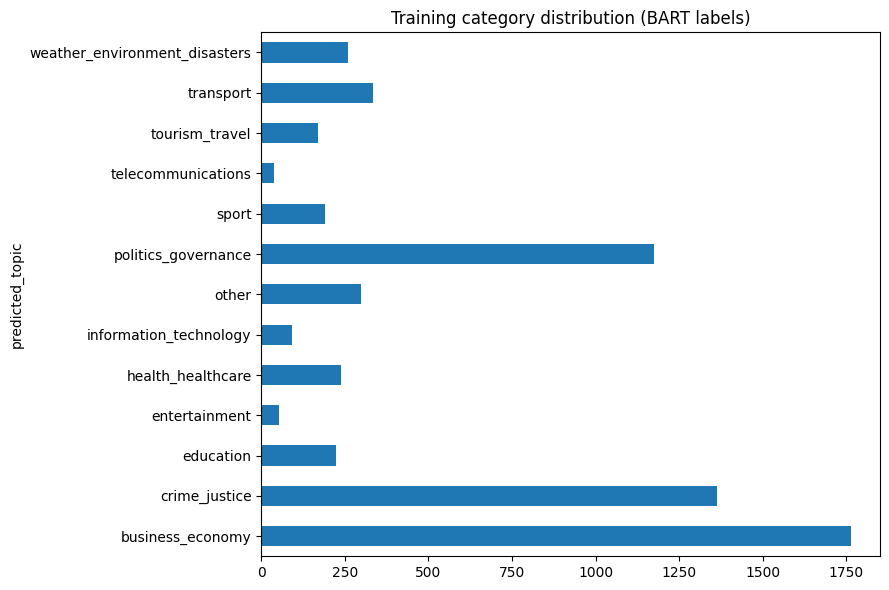

Training contains 6,197 articles. business_economy has 1,763, while telecommunications has 38. This observed imbalance motivates macro F1 and class weighting; its effect on errors is examined later rather than assumed.

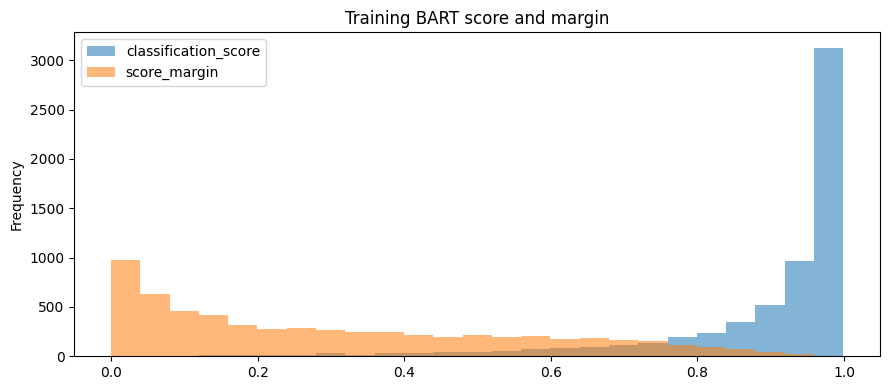

3,156/6,197 training articles (50.9%) pass score ≥0.70 and margin ≥0.20. Median score is 0.960; median margin is 0.241. A high ranking score is not evidence of independently verified correctness.

In [ ]:
counts=train.predicted_topic.value_counts().reindex(TOPICS,fill_value=0)

counts.plot.barh(figsize=(9,6),title='Training category distribution (BART labels)')

figure('category_distribution',f'Training contains {len(train):,} articles. {counts.idxmax()} has {counts.max():,}, while {counts.idxmin()} has {counts.min():,}. This observed imbalance motivates macro F1 and class weighting; its effect on errors is examined later rather than assumed.')

train[['classification_score','score_margin']].plot.hist(bins=25,alpha=.55,figsize=(9,4),title='Training BART score and margin')

figure('bart_confidence',f'{len(seed):,}/{len(train):,} training articles ({len(seed)/len(train):.1%}) pass score ≥0.70 and margin ≥0.20. Median score is {train.classification_score.median():.3f}; median margin is {train.score_margin.median():.3f}. A high ranking score is not evidence of independently verified correctness.')


## 7. TF-IDF feature extraction


### Step 7.1 — Build a Shared TF-IDF Classification Pipeline

- Convert article text into numeric features using individual words and two-word phrases.
- Keep up to 12,000 features and ignore terms that appear in fewer than two articles.
- Pass the resulting features to whichever classifier is supplied.

In [ ]:
def pipeline(clf):
    return Pipeline([('tfidf',TfidfVectorizer(max_features=CONFIG['features'],min_df=2,
        ngram_range=(1,2),sublinear_tf=True,strip_accents='unicode',dtype=np.float32)),('classifier',clf)])


### Step 7.2 — Define the Classifier Pipelines

- Set up four classifiers: Logistic Regression, Random Forest, XGBoost, and LinearSVC.
- Create a fresh pipeline on demand for each classifier, using the same TF-IDF settings.

In [ ]:
def factories():
    return {
      'Logistic regression':lambda:pipeline(LogisticRegression(C=2,max_iter=1200,class_weight='balanced',random_state=SEED)),
      'Random forest':lambda:pipeline(RandomForestClassifier(n_estimators=CONFIG['rf_trees'],min_samples_leaf=2,class_weight='balanced_subsample',n_jobs=2,random_state=SEED)),
      'XGBoost':lambda:pipeline(XGBClassifier(n_estimators=CONFIG['xgb_trees'],max_depth=4,learning_rate=.08,subsample=.85,colsample_bytree=.8,tree_method='hist',objective='multi:softprob',num_class=K,eval_metric='mlogloss',n_jobs=2,random_state=SEED)),
      'LinearSVC':lambda:pipeline(LinearSVC(C=1,class_weight='balanced',random_state=SEED,max_iter=4000))}


### Step 7.3 — Set the Base Model Order

- List the base models in the order used later: Logistic Regression, Random Forest, and XGBoost.
- LinearSVC is available from Step 7.2 and is outside this base model list.

In [ ]:
BASE_ORDER=['Logistic regression','Random forest','XGBoost']


### Step 7.4 — Define a Reusable Function for Training Classifiers

- Create a fresh TF-IDF and classifier pipeline for the requested model.
- Convert topic names in `target` into numeric class IDs.
- Pass along any article weights. For XGBoost, also give articles from rarer topics more weight to balance their contribution.
- Fit the pipeline on the article text and target labels, then verify that the fitted model includes every expected topic.

In [ ]:
def fitted_model(name,frame,weights=None):
    model=factories()[name]()
    y=encoder.transform(frame.target)
    kwargs={}
    if weights is not None: kwargs['classifier__sample_weight']=np.asarray(weights)
    if name=='XGBoost':
        # All categories must remain present; additionally balance class contributions.
        from sklearn.utils.class_weight import compute_sample_weight
        cw=compute_sample_weight('balanced',y)
        kwargs['classifier__sample_weight']=cw*(np.asarray(weights) if weights is not None else 1)
    model.fit(frame.article,y,**kwargs)
    assert np.array_equal(model.classes_,np.arange(K))
    return model


### Step 7.5 — Assign Training Labels and Initial Weights to Seed Articles

- Use each seed article’s BART-predicted topic as its training label (`target`).
- Set each seed article’s initial sample weight to `1.0`.

In [ ]:
seed['target']=seed.predicted_topic

seed['sample_weight']=1.


## 8. Initial Classifier Training and Stacking


### Step 8.1 — Create Group-Aware Folds for Out-of-Fold Predictions

- Choose up to three folds, based on how many distinct duplicate groups the rarest topic has.
- Keep each duplicate group together and check that every fold’s training portion contains all topics.
- Return the folds so each article can receive predictions from models trained on other groups.

In [ ]:
def safe_folds(frame):
    n=min(CONFIG['oof_folds'],int(frame.groupby('target').duplicate_group.nunique().min()))
    assert n>=2
    folds=list(StratifiedGroupKFold(n,shuffle=True,random_state=SEED).split(frame.article,frame.target,frame.duplicate_group))
    for tr,va in folds:
        assert set(frame.iloc[tr].duplicate_group).isdisjoint(frame.iloc[va].duplicate_group)
        assert set(frame.iloc[tr].target)==set(TOPICS), 'Rare class missing in OOF training fold'
    return folds


### Step 8.2 — Define Model Training and Reuse Matching Saved Models

- Build a cache key from the run hash, training tag, article IDs, target labels, and sample weights.
- Load the saved model bundle if the key matches. Otherwise, continue with training.

In [ ]:
def fit_bundle(frame,tag):
    start=time.perf_counter()
    signature=hashlib.sha256((RUN_HASH+tag+frame[['doc_id','target','sample_weight']].sort_values('doc_id').to_csv(index=False)).encode()).hexdigest()
    cache=OUT/f'bundle_{signature[:16]}.joblib'
    if cache.exists():
        print('Reloading matching run cache:',tag,flush=True)
        return joblib.load(cache)
    frame=frame.reset_index(drop=True)
    assert set(frame.duplicate_group)<=set(train.duplicate_group)
    assert not set(frame.duplicate_group)&audit_groups
    folds=safe_folds(frame); fitted={}; blocks=[]; times={}
    for name in BASE_ORDER:
        t=time.perf_counter();oof=np.zeros((len(frame),K))
        for fold,(tr,va) in enumerate(folds):
            fm=fitted_model(name,frame.iloc[tr],frame.sample_weight.iloc[tr])
            oof[va]=fm.predict_proba(frame.article.iloc[va])
            print(tag,name,'OOF',fold+1,'complete',flush=True)
        fitted[name]=fitted_model(name,frame,frame.sample_weight)
        blocks.append(oof);times[name]=time.perf_counter()-t
    meta=LogisticRegression(C=1,max_iter=1200,class_weight='balanced',random_state=SEED)
    meta.fit(np.hstack(blocks),encoder.transform(frame.target),sample_weight=frame.sample_weight)
    t=time.perf_counter();fitted['LinearSVC']=fitted_model('LinearSVC',frame,frame.sample_weight)
    times['LinearSVC']=time.perf_counter()-t
    times['Stacking']=time.perf_counter()-start
    bundle={'base':fitted,'meta':meta,'base_order':BASE_ORDER,'topics':TOPICS,'fit_seconds':times,'signature':signature}
    joblib.dump(bundle,cache,compress=3)
    return bundle


### Step 8.3 — Generate Individual and Stacked Model Predictions

- Get topic probabilities from Logistic Regression, Random Forest, and XGBoost, and retrieve decision scores from LinearSVC.
- Join the three probability vectors in `BASE_ORDER` and pass them to the meta-model to produce the stacking ensemble’s topic probabilities.

In [ ]:
def outputs(bundle,texts):
    result={}
    for name,model in bundle['base'].items():
        result[name]=model.decision_function(texts) if name=='LinearSVC' else model.predict_proba(texts)
    result['Stacking']=bundle['meta'].predict_proba(np.hstack([result[n] for n in BASE_ORDER]))
    return result


### Step 8.4 — Extract the Predicted Topic, Top Score, and Score Margin

- Find the two highest scores for each article and convert the winning class ID back to its topic name.
- Return the predicted topic, its score, and the margin between the top two scores.
- The margin is a probability gap for probability-based models and a decision-score gap for LinearSVC.

In [ ]:
def summarize_scores(scores,name):
    order=np.argsort(scores,axis=1)
    return encoder.inverse_transform(order[:,-1]),scores[np.arange(len(scores)),order[:,-1]],scores[np.arange(len(scores)),order[:,-1]]-scores[np.arange(len(scores)),order[:,-2]]


### Step 8.5 — Train or Reload the Initial Models

- Call `fit_bundle` with the seed articles to obtain the initial base models and stacking meta-model.
- Reuse a matching saved bundle when available. The output shown confirms that this run loaded the saved bundle.

In [ ]:
initial=fit_bundle(seed,'initial')


Reloading matching run cache: initial


## 9. Evaluate Initial Models on the Validation Set

- Compare all models on the same 1,550 validation articles, including those with uncertain BART labels.
- Use BART pseudo-labels as the reference. The scores measure agreement with BART.
- Use the high-confidence subset for an additional comparison.

### Step 9.1 — Define Validation Metrics

- Calculate accuracy, macro precision, macro recall, macro F1, and weighted F1.
- Give all 13 topics equal weight in the macro averages. Weighted F1 gives more influence to topics with more reference articles.

In [ ]:
def metrics(y,p,weights=None):
    return dict(accuracy=accuracy_score(y,p,sample_weight=weights),
        macro_f1=f1_score(y,p,labels=TOPICS,average='macro',zero_division=0,sample_weight=weights),
        weighted_f1=f1_score(y,p,labels=TOPICS,average='weighted',zero_division=0,sample_weight=weights),
        precision=precision_score(y,p,labels=TOPICS,average='macro',zero_division=0,sample_weight=weights),
        recall=recall_score(y,p,labels=TOPICS,average='macro',zero_division=0,sample_weight=weights))


### Step 9.2 — Set Up Validation Results Storage

- Create containers for summary metrics and article-level predictions.
- Register the initial model bundle under `initial`.

In [ ]:
VALIDATION_ROWS=[]

VALIDATION_PREDICTIONS={}

BUNDLES={'initial':initial}


### Step 9.3 — Define the Validation Evaluation Function

- Define a reusable function that takes a model bundle and training-stage name so each stage can be evaluated on the same validation set.

In [ ]:
def evaluate_validation(bundle,stage):
    start=time.perf_counter();preds=outputs(bundle,validation.article)
    elapsed=time.perf_counter()-start
    for name,s in preds.items():
        p,score,margin=summarize_scores(s,name)
        row=dict(stage=stage,model=name,reference='BART pseudo-label',n=len(validation),
                 fit_seconds=bundle['fit_seconds'].get(name,np.nan),inference_seconds_all_models=elapsed,**metrics(validation.predicted_topic,p))
        VALIDATION_ROWS.append(row)
        VALIDATION_PREDICTIONS[(stage,name)]=p
        record=validation[['doc_id','description','article','predicted_topic','classification_score','score_margin','duplicate_group']].copy()
        record['prediction']=p;record['score']=score;record['prediction_margin']=margin
        record['score_type']='uncalibrated decision score' if name=='LinearSVC' else 'uncalibrated model probability'
        record['model']=name;record['stage']=stage
        record.to_csv(OUT/f'validation_{stage}_{name.replace(" ","_")}_predictions.csv',index=False)
        report=classification_report(record.predicted_topic,p,labels=TOPICS,output_dict=True,zero_division=0)
        (OUT/f'validation_{stage}_{name.replace(" ","_")}_report.json').write_text(json.dumps(report,indent=2))
    return pd.DataFrame([r for r in VALIDATION_ROWS if r['stage']==stage])


## Step 9.4 — Initial Validation Results Against BART Pseudo-Labels

- **Evaluation setup.** All five models were evaluated on the same 1,550 validation articles. The scores show how closely their predictions agreed with the topic labels generated by BART.

In [ ]:
initial_metrics=evaluate_validation(initial,'initial')

table('initial_validation_metrics',initial_metrics)


,stage,model,reference,n,fit_seconds,inference_seconds_all_models,accuracy,macro_f1,weighted_f1,precision,recall
0,initial,Logistic regression,BART pseudo-label,1550,33.284985,6.345373,0.765161,0.610442,0.756708,0.706453,0.590996
1,initial,Random forest,BART pseudo-label,1550,26.631940,6.345373,0.729677,0.502477,0.705788,0.591700,0.472923
2,initial,XGBoost,BART pseudo-label,1550,397.030731,6.345373,0.741935,0.557143,0.734755,0.581267,0.560110
3,initial,LinearSVC,BART pseudo-label,1550,5.187801,6.345373,0.767742,0.627217,0.759174,0.728237,0.602291
4,initial,Stacking,BART pseudo-label,1550,463.136743,6.345373,0.692903,0.574916,0.731427,0.570328,0.603265


## 10. Automatic Pseudo-Label Refinement

This stage proposes topic labels for uncertain articles in the training split. The stacking classifier proposes a topic, and its score, margin, and agreement with the base classifiers determine which proposed labels are used for retraining.

- **Baseline rule.** Accept a proposed label if its stacking score is at least **0.90**, its margin is at least **0.20**, and all three base classifiers (Logistic Regression, Random Forest, and XGBoost) agree with the stacking prediction.
- **Per-topic cap.** Accept at most as many articles per topic as there are seed training articles for that topic.
- **Strategy screening.** Test 12 combinations of score thresholds (**0.85, 0.90, 0.95**), margin thresholds (**0.20, 0.30**), and agreement rules (**all 3** or **at least 2 of 3** base classifiers matching stacking).
- **Model comparison.** Retrain Logistic Regression and LinearSVC for each strategy and compare their validation results. Then evaluate the best strategy, the baseline rule, and a variant that gives accepted articles less training weight. This comparison uses all five classifiers and rebuilds stacking with grouped out-of-fold predictions.
- **Evaluation scope.** Candidates come exclusively from the training split, and strategy selection uses validation results. Human audit labels and test metrics are held out of these decisions. The scores are uncalibrated, so **0.90** is a selection threshold.

### Step 10.1 — Score the Uncertain Training Articles

- Run the initial models on the uncertain articles in the training pool and store their prediction scores in `pool_scores`.

In [ ]:
pool_scores=outputs(initial,pool.article) if len(pool) else None


### Step 10.2 — Build the Candidate Label Table

- Use the stacking classifier's top prediction as the proposed topic. Record its score and the **margin**, which is the gap between its highest and second-highest scores.
- Count how many of the three base classifiers predict the same topic as stacking and store the count as `votes`.
- Keep the article ID and original BART topic alongside the proposed topic so the two labels can be compared.
- Return one row per article. The next selection step applies the score threshold, margin threshold, agreement rule, and per-topic cap.

In [ ]:
def candidates_from(bundle,frame):
    if frame.empty:return pd.DataFrame(columns=['doc_id','candidate_topic','score','margin','votes','bart_topic'])
    scores=outputs(bundle,frame.article)
    p,s,m=summarize_scores(scores['Stacking'],'Stacking')
    winners=scores['Stacking'].argmax(1)
    votes=sum((scores[n].argmax(1)==winners).astype(int) for n in BASE_ORDER)
    return pd.DataFrame({'doc_id':frame.doc_id.to_numpy(),'candidate_topic':p,'score':s,'margin':m,'votes':votes,'bart_topic':frame.predicted_topic.to_numpy()})


### Step 10.3 — Generate and Inspect Candidate Pseudo-Labels

- Run `candidates_from(initial, pool)` to generate proposed topic labels for **3,041 uncertain training articles**.

In [ ]:
candidates=candidates_from(initial,pool)

table('uncertain_candidate_predictions',candidates)


,doc_id,candidate_topic,score,margin,votes,bart_topic
0,2023-10-18-dbsjeyarajcom-3a451bcb,politics_governance,0.489745,0.312752,3,politics_governance
1,2023-10-20-dbsjeyarajcom-409c399f,politics_governance,0.829017,0.758761,3,politics_governance
2,2023-10-20-dbsjeyarajcom-987b27ad,telecommunications,0.418795,0.090703,0,politics_governance
3,2023-10-21-dbsjeyarajcom-f505546f,business_economy,0.985413,0.973801,3,business_economy
4,2023-10-22-dbsjeyarajcom-78f561c6,telecommunications,0.544654,0.294022,0,politics_governance
...,...,...,...,...,...,...
3036,2024-05-06-colombotelegraphcom-2f418b00,other,0.395173,0.189649,1,politics_governance
3037,2024-05-06-dailyftlk-b564c9ae,information_technology,0.313296,0.080731,0,transport
3038,2024-05-06-dailymirrorlk-2de2d625,other,0.448779,0.131502,1,politics_governance
3039,2024-05-06-dailymirrorlk-3431e2a0,sport,0.999060,0.998321,3,sport


### Step 10.4 — Define the Pseudo-Label Acceptance Rules

- Define `accept()` to filter the candidate table using a minimum score, a minimum margin, a base-model agreement rule, and a per topic cap.
- The default settings require a score of at least **0.90**, a margin of at least **0.20**, and agreement from **all three base classifiers** with the stacking prediction.

In [ ]:
def accept(cand,confidence=.90,margin=.20,agreement='unanimous',cap_multiplier=1.):
    chosen=cand.loc[(cand.score>=confidence)&(cand.margin>=margin)&(cand.votes>=(3 if agreement=='unanimous' else 2))].copy()
    chosen=chosen.sort_values(['score','doc_id'],ascending=[False,True])
    parts=[g.head(int(support.get(topic,0)*cap_multiplier)) for topic,g in chosen.groupby('candidate_topic')]
    return pd.concat(parts,ignore_index=True) if parts else chosen


### Step 10.5 — Expand the Training Set With Accepted Pseudo-Labels

- Combine the newly labeled articles with the seed training set.
- Return both the full expanded training set and the subset of newly added articles.

In [ ]:
def expand(accepted,weight=1.):
    added=pool.merge(accepted[['doc_id','candidate_topic']],on='doc_id',validate='one_to_one')
    added['target']=added.candidate_topic
    added['sample_weight']=weight
    result=pd.concat([seed,added],ignore_index=True)
    assert result.doc_id.is_unique
    assert set(result.duplicate_group)<=set(train.duplicate_group)
    assert not set(result.duplicate_group)&(set(validation.duplicate_group)|set(test.duplicate_group)|audit_groups)
    return result,added


### Step 10.6 — Apply the Baseline Refinement Rule

- Store the expanded training set in `baseline_expanded` and the newly added articles in `baseline_added` for later comparison.

In [ ]:
BASELINE_RULE=dict(confidence=.90,margin=.20,agreement='unanimous',cap_multiplier=1.)

baseline_accepted=accept(candidates,**BASELINE_RULE)

baseline_expanded,baseline_added=expand(baseline_accepted)

GRID_ROWS=[]

GRID_SELECTIONS={}

screen_cache={}


### Step 10.7 — Screen 12 Pseudo-Label Selection Strategies

- Combine three score thresholds (**0.85, 0.90, 0.95**), two margin thresholds (**0.20, 0.30**), and two agreement rules (**unanimous** or **majority**) to create **12 strategies**.
- Compare the strategies using the validation performance of Logistic Regression and LinearSVC trained on the resulting expanded training sets.

In [ ]:
for confidence,margin,agreement in itertools.product([.85,.90,.95],[.20,.30],['unanimous','majority']):
    rule=dict(confidence=confidence,margin=margin,agreement=agreement,cap_multiplier=1.)
    selected=accept(candidates,**rule)
    expanded,_=expand(selected)
    key=hashlib.sha256(selected[['doc_id','candidate_topic']].sort_values('doc_id').to_csv(index=False).encode()).hexdigest()
    GRID_SELECTIONS[key]=(rule,selected)
    for name in ['Logistic regression','LinearSVC']:
        if (key,name) not in screen_cache:
            t=time.perf_counter();m=fitted_model(name,expanded,expanded.sample_weight)
            p=encoder.inverse_transform(m.predict(validation.article))
            screen_cache[(key,name)]={**metrics(validation.predicted_topic,p),'fit_seconds':time.perf_counter()-t}
        GRID_ROWS.append({**rule,'selection_key':key,'model':name,'accepted':len(selected),
            'acceptance_pct':100*len(selected)/max(1,len(pool)),'unresolved':len(pool)-len(selected),
            'expanded':len(expanded),'evaluation_scope':'LR/SVC validation screening',**screen_cache[(key,name)]})
    print('Screened:',rule,'accepted',len(selected),flush=True)


Screened: {'confidence': 0.85, 'margin': 0.2, 'agreement': 'unanimous', 'cap_multiplier': 1.0} accepted 715
Screened: {'confidence': 0.85, 'margin': 0.2, 'agreement': 'majority', 'cap_multiplier': 1.0} accepted 791
Screened: {'confidence': 0.85, 'margin': 0.3, 'agreement': 'unanimous', 'cap_multiplier': 1.0} accepted 715
Screened: {'confidence': 0.85, 'margin': 0.3, 'agreement': 'majority', 'cap_multiplier': 1.0} accepted 791
Screened: {'confidence': 0.9, 'margin': 0.2, 'agreement': 'unanimous', 'cap_multiplier': 1.0} accepted 533
Screened: {'confidence': 0.9, 'margin': 0.2, 'agreement': 'majority', 'cap_multiplier': 1.0} accepted 588
Screened: {'confidence': 0.9, 'margin': 0.3, 'agreement': 'unanimous', 'cap_multiplier': 1.0} accepted 533
Screened: {'confidence': 0.9, 'margin': 0.3, 'agreement': 'majority', 'cap_multiplier': 1.0} accepted 588
Screened: {'confidence': 0.95, 'margin': 0.2, 'agreement': 'unanimous', 'cap_multiplier': 1.0} accepted 315
Screened: {'confidence': 0.95, 'marg

### Step 10.8 — Rank Validation Results and Select the Refinement Rule

- Convert the screening results into a DataFrame and display them as `ablation_grid_validation`.
- Rank the model–strategy combinations by **highest validation macro F1**. Macro F1 gives every topic equal weight, including topics with fewer articles.
- Break ties using **higher weighted F1**, followed by **shorter fit time** if both F1 scores are tied.
- Use the top-ranked row's `selection_key` to retrieve its refinement rule (`BEST_RULE`) and the candidates it accepted (`best_accepted`) for the next stage of comparison.

In [ ]:
grid=pd.DataFrame(GRID_ROWS)

table('ablation_grid_validation',grid)

best_screen=grid.sort_values(['macro_f1','weighted_f1','fit_seconds'],ascending=[False,False,True]).iloc[0]

BEST_RULE,best_accepted=GRID_SELECTIONS[best_screen.selection_key]


,confidence,margin,agreement,cap_multiplier,selection_key,model,accepted,acceptance_pct,unresolved,expanded,evaluation_scope,accuracy,macro_f1,weighted_f1,precision,recall,fit_seconds
0,0.85,0.2,unanimous,1.0,2c1bb36cc6d4edd9c99bd856d14bd7258d21204585e139...,Logistic regression,715,23.512003,2326,3871,LR/SVC validation screening,0.759355,0.612594,0.752296,0.713922,0.594974,12.865126
1,0.85,0.2,unanimous,1.0,2c1bb36cc6d4edd9c99bd856d14bd7258d21204585e139...,LinearSVC,715,23.512003,2326,3871,LR/SVC validation screening,0.766452,0.636383,0.759161,0.724213,0.614156,12.941750
2,0.85,0.2,majority,1.0,f3133ac7820d4e70dea077cd58fc0534e5774cf823297d...,Logistic regression,791,26.011181,2250,3947,LR/SVC validation screening,0.763226,0.624887,0.756817,0.708411,0.607394,12.599589
3,0.85,0.2,majority,1.0,f3133ac7820d4e70dea077cd58fc0534e5774cf823297d...,LinearSVC,791,26.011181,2250,3947,LR/SVC validation screening,0.763871,0.638228,0.757187,0.717677,0.620483,9.631317
4,0.85,0.3,unanimous,1.0,2c1bb36cc6d4edd9c99bd856d14bd7258d21204585e139...,Logistic regression,715,23.512003,2326,3871,LR/SVC validation screening,0.759355,0.612594,0.752296,0.713922,0.594974,12.865126
5,0.85,0.3,unanimous,1.0,2c1bb36cc6d4edd9c99bd856d14bd7258d21204585e139...,LinearSVC,715,23.512003,2326,3871,LR/SVC validation screening,0.766452,0.636383,0.759161,0.724213,0.614156,12.941750
6,0.85,0.3,majority,1.0,f3133ac7820d4e70dea077cd58fc0534e5774cf823297d...,Logistic regression,791,26.011181,2250,3947,LR/SVC validation screening,0.763226,0.624887,0.756817,0.708411,0.607394,12.599589
7,0.85,0.3,majority,1.0,f3133ac7820d4e70dea077cd58fc0534e5774cf823297d...,LinearSVC,791,26.011181,2250,3947,LR/SVC validation screening,0.763871,0.638228,0.757187,0.717677,0.620483,9.631317
8,0.90,0.2,unanimous,1.0,1464c410456d73f2570d000d964308f1b53a9c6d5154ea...,Logistic regression,533,17.527129,2508,3689,LR/SVC validation screening,0.763871,0.614797,0.756822,0.703647,0.598579,15.040200
9,0.90,0.2,unanimous,1.0,1464c410456d73f2570d000d964308f1b53a9c6d5154ea...,LinearSVC,533,17.527129,2508,3689,LR/SVC validation screening,0.767097,0.638425,0.760077,0.723276,0.619043,9.936171


Best rule

In [ ]:
grid = pd.DataFrame(GRID_ROWS)

ranked_grid = grid.sort_values(
    ["macro_f1", "weighted_f1", "fit_seconds"],
    ascending=[False, False, True],
)

table("ablation_grid_validation", ranked_grid)

best_screen = ranked_grid.iloc[0]
BEST_RULE, best_accepted = GRID_SELECTIONS[best_screen.selection_key]

,confidence,margin,agreement,cap_multiplier,selection_key,model,accepted,acceptance_pct,unresolved,expanded,evaluation_scope,accuracy,macro_f1,weighted_f1,precision,recall,fit_seconds
17,0.95,0.2,unanimous,1.0,b5af49a1f3da6d5c7151d2f4eaee01a3fff01f2bf36ad8...,LinearSVC,315,10.358435,2726,3471,LR/SVC validation screening,0.770968,0.642161,0.763708,0.728344,0.621929,8.950686
21,0.95,0.3,unanimous,1.0,b5af49a1f3da6d5c7151d2f4eaee01a3fff01f2bf36ad8...,LinearSVC,315,10.358435,2726,3471,LR/SVC validation screening,0.770968,0.642161,0.763708,0.728344,0.621929,8.950686
19,0.95,0.2,majority,1.0,258727f705cc609a8ec944becf0b3ff422277a0ff92751...,LinearSVC,335,11.016113,2706,3491,LR/SVC validation screening,0.771613,0.640537,0.764380,0.724926,0.621918,10.208898
23,0.95,0.3,majority,1.0,258727f705cc609a8ec944becf0b3ff422277a0ff92751...,LinearSVC,335,11.016113,2706,3491,LR/SVC validation screening,0.771613,0.640537,0.764380,0.724926,0.621918,10.208898
11,0.90,0.2,majority,1.0,99586951b6a057517e59c64f1624f18d08503f23273d8c...,LinearSVC,588,19.335745,2453,3744,LR/SVC validation screening,0.767097,0.640422,0.760483,0.720172,0.622435,9.278948
15,0.90,0.3,majority,1.0,99586951b6a057517e59c64f1624f18d08503f23273d8c...,LinearSVC,588,19.335745,2453,3744,LR/SVC validation screening,0.767097,0.640422,0.760483,0.720172,0.622435,9.278948
9,0.90,0.2,unanimous,1.0,1464c410456d73f2570d000d964308f1b53a9c6d5154ea...,LinearSVC,533,17.527129,2508,3689,LR/SVC validation screening,0.767097,0.638425,0.760077,0.723276,0.619043,9.936171
13,0.90,0.3,unanimous,1.0,1464c410456d73f2570d000d964308f1b53a9c6d5154ea...,LinearSVC,533,17.527129,2508,3689,LR/SVC validation screening,0.767097,0.638425,0.760077,0.723276,0.619043,9.936171
3,0.85,0.2,majority,1.0,f3133ac7820d4e70dea077cd58fc0534e5774cf823297d...,LinearSVC,791,26.011181,2250,3947,LR/SVC validation screening,0.763871,0.638228,0.757187,0.717677,0.620483,9.631317
7,0.85,0.3,majority,1.0,f3133ac7820d4e70dea077cd58fc0534e5774cf823297d...,LinearSVC,791,26.011181,2250,3947,LR/SVC validation screening,0.763871,0.638228,0.757187,0.717677,0.620483,9.631317


## 11. Coverage and Reliability of Automatic Pseudo-Labeling

- **Coverage** is the percentage of the 3,041 uncertain training articles accepted by a rule after applying its per-topic cap. For example, accepting 715 articles gives 23.51% coverage.
- **Reliability indicators** include agreement among the base classifiers, agreement with BART, prediction stability, and the distribution of stacking scores. These describe how strongly or consistently the models support the proposed labels. Human-reviewed labels provide an independent reference for measuring correctness.
- **Coverage trade-off.** Stricter rules can leave fewer articles available for retraining. Whether the retained labels are more accurate requires independent evaluation.

### Step 11.1 — Compare Rule Coverage and Visualize Stacking Scores

- Keep one row per acceptance rule in `refinement_acceptance_statistics`. Logistic Regression and LinearSVC have separate validation scores, but both use the same selected articles for each rule, so the coverage figures only need to be counted once.
- **Line chart.** Compare how many articles each rule accepts at stacking score thresholds of **0.85, 0.90, and 0.95**. Each line represents a different combination of margin threshold and agreement requirement.
- **Histogram.** Show the distribution of stacking scores for all candidate articles before filtering. Use it to see where the score thresholds fall within the candidate pool. Final acceptance also depends on the margin, model votes, and per-topic cap.

,confidence,margin,agreement,cap_multiplier,selection_key,model,accepted,acceptance_pct,unresolved,expanded,evaluation_scope,accuracy,macro_f1,weighted_f1,precision,recall,fit_seconds
0,0.85,0.2,unanimous,1.0,2c1bb36cc6d4edd9c99bd856d14bd7258d21204585e139...,Logistic regression,715,23.512003,2326,3871,LR/SVC validation screening,0.759355,0.612594,0.752296,0.713922,0.594974,12.865126
2,0.85,0.2,majority,1.0,f3133ac7820d4e70dea077cd58fc0534e5774cf823297d...,Logistic regression,791,26.011181,2250,3947,LR/SVC validation screening,0.763226,0.624887,0.756817,0.708411,0.607394,12.599589
4,0.85,0.3,unanimous,1.0,2c1bb36cc6d4edd9c99bd856d14bd7258d21204585e139...,Logistic regression,715,23.512003,2326,3871,LR/SVC validation screening,0.759355,0.612594,0.752296,0.713922,0.594974,12.865126
6,0.85,0.3,majority,1.0,f3133ac7820d4e70dea077cd58fc0534e5774cf823297d...,Logistic regression,791,26.011181,2250,3947,LR/SVC validation screening,0.763226,0.624887,0.756817,0.708411,0.607394,12.599589
8,0.90,0.2,unanimous,1.0,1464c410456d73f2570d000d964308f1b53a9c6d5154ea...,Logistic regression,533,17.527129,2508,3689,LR/SVC validation screening,0.763871,0.614797,0.756822,0.703647,0.598579,15.040200
10,0.90,0.2,majority,1.0,99586951b6a057517e59c64f1624f18d08503f23273d8c...,Logistic regression,588,19.335745,2453,3744,LR/SVC validation screening,0.765161,0.617281,0.758156,0.705899,0.601519,12.906501
12,0.90,0.3,unanimous,1.0,1464c410456d73f2570d000d964308f1b53a9c6d5154ea...,Logistic regression,533,17.527129,2508,3689,LR/SVC validation screening,0.763871,0.614797,0.756822,0.703647,0.598579,15.040200
14,0.90,0.3,majority,1.0,99586951b6a057517e59c64f1624f18d08503f23273d8c...,Logistic regression,588,19.335745,2453,3744,LR/SVC validation screening,0.765161,0.617281,0.758156,0.705899,0.601519,12.906501
16,0.95,0.2,unanimous,1.0,b5af49a1f3da6d5c7151d2f4eaee01a3fff01f2bf36ad8...,Logistic regression,315,10.358435,2726,3471,LR/SVC validation screening,0.765161,0.615812,0.758016,0.705543,0.599540,15.557612
18,0.95,0.2,majority,1.0,258727f705cc609a8ec944becf0b3ff422277a0ff92751...,Logistic regression,335,11.016113,2706,3491,LR/SVC validation screening,0.768387,0.627936,0.761607,0.712104,0.609986,12.601405


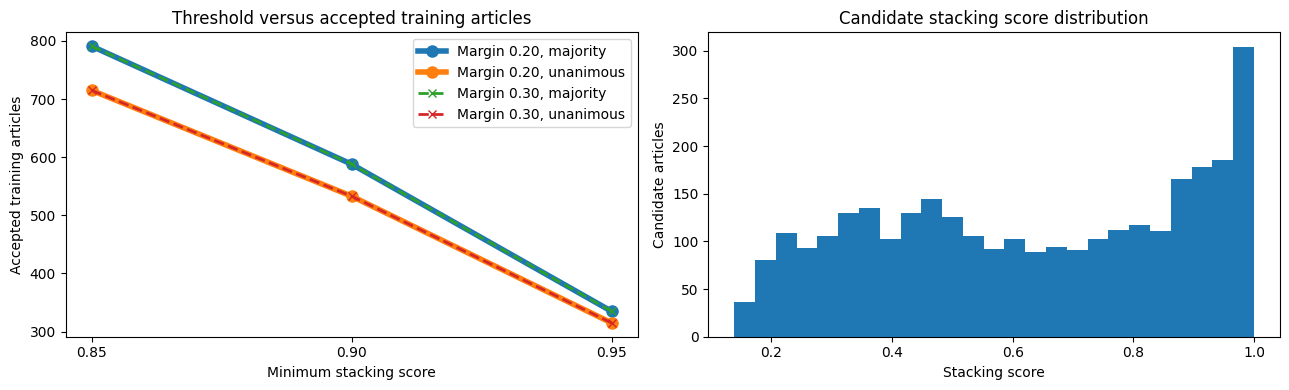

Across 12 acceptance rules, 315–791 of 3,041 candidates are accepted. The baseline rule accepts 533 (17.5%), leaving 2,508 unresolved. Voting requirements and per-topic caps also affect these counts. Stacking scores are uncalibrated, and the charts describe coverage and the distribution of candidate scores.

In [ ]:
coverage = grid.drop_duplicates(
    ["confidence", "margin", "agreement", "cap_multiplier"]
).copy()

table("refinement_acceptance_statistics", coverage)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

styles = {
    0.20: {"linestyle": "-", "linewidth": 4, "marker": "o", "markersize": 8},
    0.30: {"linestyle": "--", "linewidth": 2, "marker": "x", "markersize": 6},
}

# Plot accepted article counts for each margin and agreement setting.
for (margin, agreement), group in coverage.groupby(
    ["margin", "agreement"], sort=True
):
    group = group.sort_values("confidence")
    axes[0].plot(
        group["confidence"],
        group["accepted"],
        label=f"Margin {margin:.2f}, {agreement}",
        **styles[margin],
    )

axes[0].set_title("Threshold versus accepted training articles")
axes[0].set_xlabel("Minimum stacking score")
axes[0].set_ylabel("Accepted training articles")
axes[0].set_xticks([0.85, 0.90, 0.95])
axes[0].legend()

# Show stacking scores across all candidates before filtering.
axes[1].hist(candidates["score"], bins=25)
axes[1].set_title("Candidate stacking score distribution")
axes[1].set_xlabel("Stacking score")
axes[1].set_ylabel("Candidate articles")

fig.tight_layout()

pool_count = len(pool)
baseline_count = len(baseline_accepted)
baseline_coverage = baseline_count / max(1, pool_count)

figure(
    "coverage_thresholds",
    f"Across {len(coverage)} acceptance rules, "
    f"{coverage['accepted'].min():,}–{coverage['accepted'].max():,} "
    f"of {pool_count:,} candidates are accepted. "
    f"The baseline rule accepts {baseline_count:,} ({baseline_coverage:.1%}), "
    f"leaving {pool_count - baseline_count:,} unresolved. "
    "Voting requirements and per-topic caps also affect these counts. "
    "Stacking scores are uncalibrated, and the charts describe coverage "
    "and the distribution of candidate scores."
)

proxy = []

### Step 11.2 — Compare Agreement Among Accepted Pseudo-Labels

- Reapply each acceptance rule and record how many uncertain training articles it accepts.
- **BART agreement** is the percentage of accepted articles whose proposed topic matches their original BART topic.
- **Mean votes** is the average number of base classifiers that agree with stacking, out of three. **Mean score** is the average stacking score for the accepted articles.
- At a score threshold of **0.85** and a margin of **0.20**, majority agreement accepts **791 articles**, compared with **715** under unanimous agreement. The share of accepted labels matching BART drops from **80.42%** to **78.76%**.
- At the **0.85** score threshold, raising the margin from **0.20** to **0.30** produces the same acceptance counts and agreement statistics for both voting rules.

,confidence,margin,agreement,accepted,bart_agreement,mean_votes,mean_score
0,0.85,0.2,unanimous,715,0.804196,3.000000,0.938501
1,0.85,0.2,majority,791,0.787611,2.902655,0.937319
2,0.85,0.3,unanimous,715,0.804196,3.000000,0.938501
3,0.85,0.3,majority,791,0.787611,2.902655,0.937319
4,0.90,0.2,unanimous,533,0.812383,3.000000,0.959798
5,0.90,0.2,majority,588,0.799320,2.904762,0.958308
6,0.90,0.3,unanimous,533,0.812383,3.000000,0.959798
7,0.90,0.3,majority,588,0.799320,2.904762,0.958308
8,0.95,0.2,unanimous,315,0.825397,3.000000,0.983967
9,0.95,0.2,majority,335,0.814925,2.937313,0.983083


Text(0, 0.5, 'Agreement with uncertain BART labels')

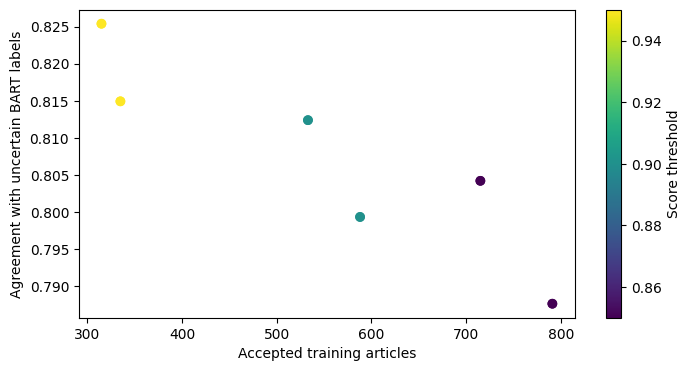

In [ ]:
for _,r in coverage.iterrows():
    chosen=accept(candidates,confidence=r.confidence,margin=r.margin,agreement=r.agreement,cap_multiplier=r.cap_multiplier)
    proxy.append(dict(confidence=r.confidence,margin=r.margin,agreement=r.agreement,accepted=len(chosen),
        bart_agreement=(chosen.candidate_topic==chosen.bart_topic).mean() if len(chosen) else np.nan,
        mean_votes=chosen.votes.mean(),mean_score=chosen.score.mean()))

proxy=pd.DataFrame(proxy)

table('coverage_reliability_proxies',proxy)

plt.figure(figsize=(8,4))

plt.scatter(proxy.accepted,proxy.bart_agreement,c=proxy.confidence,cmap='viridis')

plt.colorbar(label='Score threshold')

plt.xlabel('Accepted training articles')

plt.ylabel('Agreement with uncertain BART labels')


## 12. Build the Expanded Training Datasets

- Combine the seed training articles with the uncertain training articles accepted by each pseudo-labeling rule.


### Step 12.1 — Assemble Training Sets and Track Label Sources

- Build `baseline_refined`, `selected_refined`, and `weighted_refined`, then store them in `TRAINING_SETS`. The training tables contain only training articles.

,doc_id,duplicate_group,predicted_topic,target,sample_weight
0,2022-07-12-newsfirstlk-c83f4c6f,2022-07-12-newsfirstlk-c83f4c6f,sport,sport,1.0
1,2023-10-07-newsfirstlk-ddd24a07,2023-10-07-newsfirstlk-ddd24a07,sport,sport,1.0
2,2023-10-21-dbsjeyarajcom-262b18e4,2023-10-21-dbsjeyarajcom-262b18e4,crime_justice,crime_justice,1.0
3,2023-10-21-dbsjeyarajcom-f837824e,2023-10-21-dbsjeyarajcom-f837824e,politics_governance,politics_governance,1.0
4,2023-10-24-dbsjeyarajcom-41cb64ba,2023-10-24-dbsjeyarajcom-41cb64ba,crime_justice,crime_justice,1.0
...,...,...,...,...,...
3684,2024-05-03-islandlk-ed0082b7,2024-05-03-islandlk-ed0082b7,tourism_travel,tourism_travel,1.0
3685,2024-05-06-adaderanalk-33e9ffbf,2024-05-06-adaderanalk-33e9ffbf,tourism_travel,tourism_travel,1.0
3686,2024-05-06-adaderanalk-3abe719c,2024-05-06-adaderanalk-3abe719c,business_economy,business_economy,1.0
3687,2024-05-06-adaderanalk-d4cba43c,2024-05-06-adaderanalk-d4cba43c,crime_justice,crime_justice,1.0


,doc_id,duplicate_group,predicted_topic,target,sample_weight
0,2022-07-12-newsfirstlk-c83f4c6f,2022-07-12-newsfirstlk-c83f4c6f,sport,sport,1.0
1,2023-10-07-newsfirstlk-ddd24a07,2023-10-07-newsfirstlk-ddd24a07,sport,sport,1.0
2,2023-10-21-dbsjeyarajcom-262b18e4,2023-10-21-dbsjeyarajcom-262b18e4,crime_justice,crime_justice,1.0
3,2023-10-21-dbsjeyarajcom-f837824e,2023-10-21-dbsjeyarajcom-f837824e,politics_governance,politics_governance,1.0
4,2023-10-24-dbsjeyarajcom-41cb64ba,2023-10-24-dbsjeyarajcom-41cb64ba,crime_justice,crime_justice,1.0
...,...,...,...,...,...
3466,2024-05-03-islandlk-ed0082b7,2024-05-03-islandlk-ed0082b7,tourism_travel,tourism_travel,1.0
3467,2024-05-06-adaderanalk-33e9ffbf,2024-05-06-adaderanalk-33e9ffbf,tourism_travel,tourism_travel,1.0
3468,2024-05-06-adaderanalk-3abe719c,2024-05-06-adaderanalk-3abe719c,business_economy,business_economy,1.0
3469,2024-05-06-adaderanalk-d4cba43c,2024-05-06-adaderanalk-d4cba43c,crime_justice,crime_justice,1.0


,doc_id,duplicate_group,predicted_topic,target,sample_weight
0,2022-07-12-newsfirstlk-c83f4c6f,2022-07-12-newsfirstlk-c83f4c6f,sport,sport,1.0
1,2023-10-07-newsfirstlk-ddd24a07,2023-10-07-newsfirstlk-ddd24a07,sport,sport,1.0
2,2023-10-21-dbsjeyarajcom-262b18e4,2023-10-21-dbsjeyarajcom-262b18e4,crime_justice,crime_justice,1.0
3,2023-10-21-dbsjeyarajcom-f837824e,2023-10-21-dbsjeyarajcom-f837824e,politics_governance,politics_governance,1.0
4,2023-10-24-dbsjeyarajcom-41cb64ba,2023-10-24-dbsjeyarajcom-41cb64ba,crime_justice,crime_justice,1.0
...,...,...,...,...,...
3466,2024-05-03-islandlk-ed0082b7,2024-05-03-islandlk-ed0082b7,tourism_travel,tourism_travel,0.5
3467,2024-05-06-adaderanalk-33e9ffbf,2024-05-06-adaderanalk-33e9ffbf,tourism_travel,tourism_travel,0.5
3468,2024-05-06-adaderanalk-3abe719c,2024-05-06-adaderanalk-3abe719c,business_economy,business_economy,0.5
3469,2024-05-06-adaderanalk-d4cba43c,2024-05-06-adaderanalk-d4cba43c,crime_justice,crime_justice,0.5


,doc_id,predicted_topic,classification_score,score_margin,duplicate_group,partition,candidate_topic,score,margin,votes,label_provenance
0,2022-07-12-newsfirstlk-c83f4c6f,sport,0.973931,0.525263,2022-07-12-newsfirstlk-c83f4c6f,train,NaN,NaN,NaN,NaN,confident_BART_seed
1,2023-10-07-newsfirstlk-ddd24a07,sport,0.982541,0.312853,2023-10-07-newsfirstlk-ddd24a07,train,NaN,NaN,NaN,NaN,confident_BART_seed
2,2023-10-18-dbsjeyarajcom-3a451bcb,politics_governance,0.912358,0.053936,2023-10-18-dbsjeyarajcom-3a451bcb,train,NaN,NaN,NaN,NaN,unresolved
3,2023-10-18-dbsjeyarajcom-d4bba182,politics_governance,0.959269,0.127749,2023-10-18-dbsjeyarajcom-d4bba182,test,NaN,NaN,NaN,NaN,reserved_evaluation
4,2023-10-19-dbsjeyarajcom-15c6a51b,politics_governance,0.975460,0.016864,2023-10-19-dbsjeyarajcom-15c6a51b,test,NaN,NaN,NaN,NaN,reserved_evaluation
...,...,...,...,...,...,...,...,...,...,...,...
9995,2024-05-06-dailymirrorlk-3ad28d9c,weather_environment_disasters,0.973139,0.591689,2024-05-06-dailymirrorlk-3ad28d9c,validation,NaN,NaN,NaN,NaN,reserved_evaluation
9996,2024-05-06-dailymirrorlk-3fbbb81c,health_healthcare,0.954890,0.307649,2024-05-06-dailymirrorlk-3fbbb81c,train,NaN,NaN,NaN,NaN,confident_BART_seed
9997,2024-05-06-dailymirrorlk-4af2bc9d,crime_justice,0.942876,0.724790,2024-05-06-dailymirrorlk-4af2bc9d,train,NaN,NaN,NaN,NaN,confident_BART_seed
9998,2024-05-06-dailymirrorlk-5633a584,sport,0.993487,0.706968,2024-05-06-dailymirrorlk-5633a584,test,NaN,NaN,NaN,NaN,reserved_evaluation


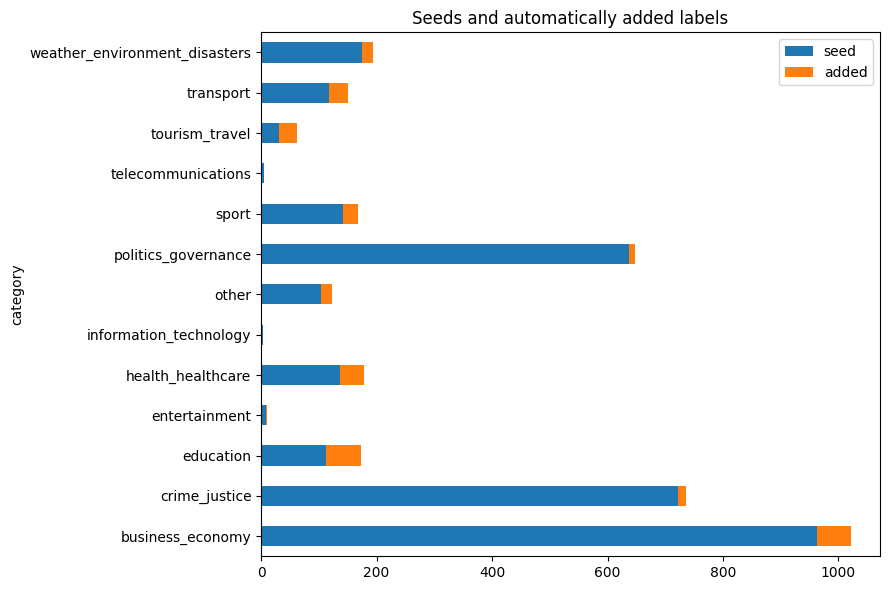

The screening-selected rule expands training from 3,156 to 3,471, adding 315 articles (10.0% growth). 2 categories receive no new articles. Added labels remain machine-generated; count increases alone do not demonstrate benefit.

In [ ]:
best_expanded,best_added=expand(best_accepted)

weighted_expanded,_=expand(best_accepted,weight=.5)

TRAINING_SETS={'baseline_refined':baseline_expanded,'selected_refined':best_expanded,'weighted_refined':weighted_expanded}

for stage,frame in TRAINING_SETS.items():
    table('training_'+stage,frame[['doc_id','duplicate_group','predicted_topic','target','sample_weight']])

provenance=df[['doc_id','predicted_topic','classification_score','score_margin','duplicate_group','partition']].merge(best_accepted[['doc_id','candidate_topic','score','margin','votes']],on='doc_id',how='left',validate='one_to_one')

provenance['label_provenance']=np.where(provenance.partition.ne('train'),'reserved_evaluation',np.where(provenance.doc_id.isin(seed.doc_id),'confident_BART_seed',np.where(provenance.candidate_topic.notna(),'ensemble_pseudo_label','unresolved')))

table('articles_with_refinement_provenance',provenance)

composition=pd.DataFrame({'category':TOPICS,'seed':support.values,'added':best_added.target.value_counts().reindex(TOPICS,fill_value=0).values})

composition.set_index('category').plot.barh(stacked=True,figsize=(9,6),title='Seeds and automatically added labels')

figure('seed_added_counts',f'The screening-selected rule expands training from {len(seed):,} to {len(best_expanded):,}, adding {len(best_added):,} articles ({len(best_added)/len(seed):.1%} growth). {(composition.added==0).sum()} categories receive no new articles. Added labels remain machine-generated; count increases alone do not demonstrate benefit.')


Ones where target is different from seeded values from BART

In [ ]:
baseline_refined = TRAINING_SETS["baseline_refined"]

display(
    baseline_refined.loc[
        baseline_refined["predicted_topic"] != baseline_refined["target"],
        ["doc_id", "predicted_topic", "target", "sample_weight"],
    ]
)

,doc_id,predicted_topic,target,sample_weight
3163,2024-01-05-islandlk-e2c22ad1,politics_governance,crime_justice,1.0
3165,2024-01-08-dailyftlk-bc39c0ca,crime_justice,other,1.0
3169,2024-01-11-dailyftlk-1566c99a,health_healthcare,business_economy,1.0
3170,2024-01-11-dailyftlk-4cee11c9,crime_justice,business_economy,1.0
3171,2024-01-12-economynextcom-4a811a96,tourism_travel,business_economy,1.0
...,...,...,...,...
3639,2024-04-20-dailyftlk-46f51e9d,information_technology,education,1.0
3644,2024-04-21-islandlk-b4524ced,other,health_healthcare,1.0
3646,2024-04-22-islandlk-a28b17f6,education,other,1.0
3648,2024-04-23-dailymirrorlk-07b57543,other,transport,1.0


## 13. Retrain Classifiers on the Refined Training Sets

- Train all five classifiers for the **baseline**, **screening-selected**, and **weighted** training setups. The weighted setup gives each newly added article a sample weight of **0.5**, while seed articles keep a weight of **1.0**.

### Step 13.1 — Fit or Reuse Models and Evaluate on Validation


In [ ]:
fit_reuse={}

for stage,frame in TRAINING_SETS.items():
    key=digest(frame[['doc_id','target','sample_weight']].sort_values('doc_id').to_csv(index=False))
    if key not in fit_reuse: fit_reuse[key]=fit_bundle(frame,stage)
    BUNDLES[stage]=fit_reuse[key]
    evaluate_validation(BUNDLES[stage],stage)


Reloading matching run cache: baseline_refined
Reloading matching run cache: selected_refined
Reloading matching run cache: weighted_refined


## 14. Compare Initial and Refined Classifiers on Validation

- Compare each classifier trained on the seed set with its versions trained on the baseline-refined, screening-selected, and weighted training sets.

### Step 14.1 — Plot Validation Macro F1 and Identify the Leading Setup

- Combine the validation results into `model_comparison_validation`, with one row per classifier and training setup.

,stage,model,reference,n,fit_seconds,inference_seconds_all_models,accuracy,macro_f1,weighted_f1,precision,recall
0,initial,Logistic regression,BART pseudo-label,1550,33.284985,6.345373,0.765161,0.610442,0.756708,0.706453,0.590996
1,initial,Random forest,BART pseudo-label,1550,26.631940,6.345373,0.729677,0.502477,0.705788,0.591700,0.472923
2,initial,XGBoost,BART pseudo-label,1550,397.030731,6.345373,0.741935,0.557143,0.734755,0.581267,0.560110
3,initial,LinearSVC,BART pseudo-label,1550,5.187801,6.345373,0.767742,0.627217,0.759174,0.728237,0.602291
4,initial,Stacking,BART pseudo-label,1550,463.136743,6.345373,0.692903,0.574916,0.731427,0.570328,0.603265
5,baseline_refined,Logistic regression,BART pseudo-label,1550,32.733655,5.429594,0.763871,0.614797,0.756822,0.703647,0.598579
6,baseline_refined,Random forest,BART pseudo-label,1550,33.859286,5.429594,0.740645,0.542260,0.721596,0.648605,0.511122
7,baseline_refined,XGBoost,BART pseudo-label,1550,466.843833,5.429594,0.739355,0.556411,0.732650,0.582102,0.557492
8,baseline_refined,LinearSVC,BART pseudo-label,1550,7.357171,5.429594,0.767097,0.638425,0.760077,0.723276,0.619043
9,baseline_refined,Stacking,BART pseudo-label,1550,541.848396,5.429594,0.712903,0.584345,0.747028,0.587085,0.615832


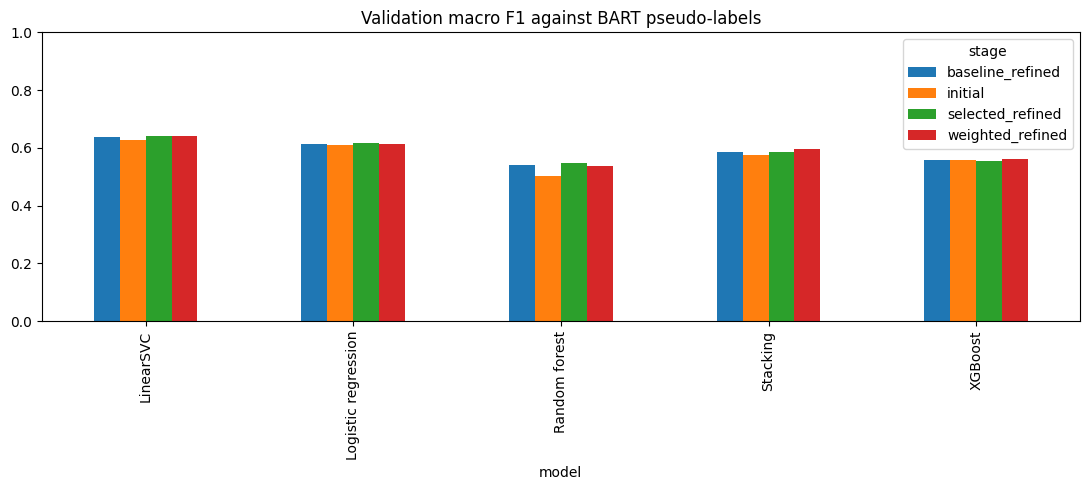

Highest validation macro F1 is 0.6422 for LinearSVC (selected_refined). Scores include all 13 categories and 1,550 validation articles. This ranks BART-reference agreement, not human accuracy. Class-specific results below show whether overall changes conceal declines.

In [ ]:
comparison=pd.DataFrame(VALIDATION_ROWS)

table('model_comparison_validation',comparison)

comparison.pivot(index='model',columns='stage',values='macro_f1').plot.bar(figsize=(11,5),ylim=(0,1),title='Validation macro F1 against BART pseudo-labels')

leader=comparison.sort_values(['macro_f1','weighted_f1','fit_seconds'],ascending=[False,False,True]).iloc[0]

figure('model_comparison',f'Highest validation macro F1 is {leader.macro_f1:.4f} for {leader.model} ({leader.stage}). Scores include all {K} categories and {len(validation):,} validation articles. This ranks BART-reference agreement, not human accuracy. Class-specific results below show whether overall changes conceal declines.')


## 15. Ablation Experiments — What Changes Validation Performance?

- **Screen the acceptance rules.** Vary the minimum stacking score, the margin between the top two scores, and the agreement requirement. Keep the seed articles, candidate predictions, and validation articles fixed.
- **Compare seed-only and expanded training.** Compare each classifier's initial result with its refined results to see how adding pseudo-labeled articles affects validation macro F1.
- **Test the effect of sample weighting.** Compare the selected and weighted setups. Both use the same articles and labels. The added articles have weight **1.0** in the selected setup and **0.5** in the weighted setup.
- **Compare individual classifiers with stacking.** Within each training setup, compare the validation scores of the individual classifiers and the stacking ensemble.
- **Explain why the margin settings overlap.** When class scores sum to **1**, a top score of **0.85** leaves at most **0.15** for the runner-up. The margin is therefore at least **0.70**, so any candidate that clears the score threshold also clears both tested margin thresholds (**0.20** and **0.30**).

### Step 15.1 — Summarize the Training Setups and Plot Screening Results

- Add the training article count and the weight assigned to newly accepted pseudo-labels to the validation results table. The initial setup records a pseudo-label weight of **0** because it contains no newly added articles. Its seed articles still have weight **1.0**.
- Plot the **highest validation macro F1** at each stacking score threshold for majority and unanimous agreement. Each point takes the maximum across both screened classifiers (Logistic Regression and LinearSVC) and both margin settings.
- The best screening result was **0.6422 macro F1**, achieved by **LinearSVC** at a score threshold of **0.95** with unanimous agreement. Both margin settings selected the same **315 articles** and tied.

,stage,model,reference,n,fit_seconds,inference_seconds_all_models,accuracy,macro_f1,weighted_f1,precision,recall,training_articles,pseudo_weight
0,initial,Logistic regression,BART pseudo-label,1550,33.284985,6.345373,0.765161,0.610442,0.756708,0.706453,0.590996,3156,0.0
1,initial,Random forest,BART pseudo-label,1550,26.631940,6.345373,0.729677,0.502477,0.705788,0.591700,0.472923,3156,0.0
2,initial,XGBoost,BART pseudo-label,1550,397.030731,6.345373,0.741935,0.557143,0.734755,0.581267,0.560110,3156,0.0
3,initial,LinearSVC,BART pseudo-label,1550,5.187801,6.345373,0.767742,0.627217,0.759174,0.728237,0.602291,3156,0.0
4,initial,Stacking,BART pseudo-label,1550,463.136743,6.345373,0.692903,0.574916,0.731427,0.570328,0.603265,3156,0.0
5,baseline_refined,Logistic regression,BART pseudo-label,1550,32.733655,5.429594,0.763871,0.614797,0.756822,0.703647,0.598579,3689,1.0
6,baseline_refined,Random forest,BART pseudo-label,1550,33.859286,5.429594,0.740645,0.542260,0.721596,0.648605,0.511122,3689,1.0
7,baseline_refined,XGBoost,BART pseudo-label,1550,466.843833,5.429594,0.739355,0.556411,0.732650,0.582102,0.557492,3689,1.0
8,baseline_refined,LinearSVC,BART pseudo-label,1550,7.357171,5.429594,0.767097,0.638425,0.760077,0.723276,0.619043,3689,1.0
9,baseline_refined,Stacking,BART pseudo-label,1550,541.848396,5.429594,0.712903,0.584345,0.747028,0.587085,0.615832,3689,1.0


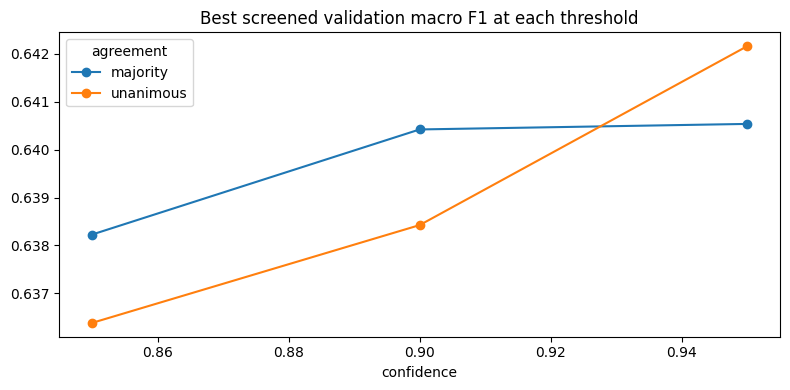

Screened LR/SVC validation macro F1 ranges from 0.6126 to 0.6422. These settings were chosen on validation only; taking the maximum creates selection optimism. No multi-seed uncertainty or second-round results are claimed. Repeating the entire fixed experiment across seeds is future work.

In [ ]:
ablation=comparison.merge(pd.DataFrame([{'stage':'initial','training_articles':len(seed),'pseudo_weight':0},
    {'stage':'baseline_refined','training_articles':len(baseline_expanded),'pseudo_weight':1},
    {'stage':'selected_refined','training_articles':len(best_expanded),'pseudo_weight':1},
    {'stage':'weighted_refined','training_articles':len(weighted_expanded),'pseudo_weight':.5}]),on='stage')

table('ablation_full_model_results',ablation)

grid.groupby(['confidence','agreement']).macro_f1.max().unstack().plot(marker='o',figsize=(8,4),title='Best screened validation macro F1 at each threshold')

figure('threshold_validation',f'Screened LR/SVC validation macro F1 ranges from {grid.macro_f1.min():.4f} to {grid.macro_f1.max():.4f}. These settings were chosen on validation only; taking the maximum creates selection optimism. No multi-seed uncertainty or second-round results are claimed. Repeating the entire fixed experiment across seeds is future work.')


Validation Macro F1 by Classifier — Selected Refinement

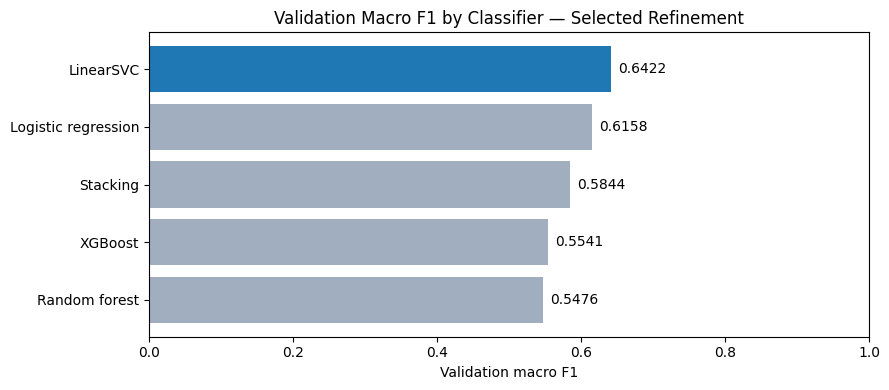

LinearSVC achieved the highest validation macro F1 (0.6422) under the selected refinement rule. All classifiers were evaluated on the same validation articles against BART pseudo-labels.

In [ ]:
selected_scores = (
    ablation.loc[
        ablation["stage"].eq("selected_refined"),
        ["model", "macro_f1"],
    ]
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)

best_model = selected_scores.iloc[0]
colors = [
    "tab:blue" if score == best_model["macro_f1"] else "#a0aec0"
    for score in selected_scores["macro_f1"]
]

fig, ax = plt.subplots(figsize=(9, 4))

bars = ax.barh(
    selected_scores["model"],
    selected_scores["macro_f1"],
    color=colors,
)
ax.invert_yaxis()
ax.bar_label(bars, fmt="%.4f", padding=5)
ax.set_xlim(0, 1)
ax.set_xlabel("Validation macro F1")
ax.set_title("Validation Macro F1 by Classifier — Selected Refinement")

fig.tight_layout()

figure(
    "selected_refined_macro_f1",
    f"{best_model['model']} achieved the highest validation macro F1 "
    f"({best_model['macro_f1']:.4f}) under the selected refinement rule. "
    "All classifiers were evaluated on the same validation articles "
    "against BART pseudo-labels.",
)

## 16. Per-Category Performance Before and After Refinement

- Compare the `initial` and `selected_refined` versions of the same classifier to see which topics gained or lost F1 after adding pseudo-labeled training articles

### Step 16.1 — Calculate Precision, Recall, and F1 for Each Topic

- Use the classifier from the top-ranked validation result. In this run, it was **LinearSVC**.
- Retrieve its predictions from the `initial` and `selected_refined` setups and calculate precision, recall, and F1 for each topic.
- Calculate `f1_difference` as **refined F1 minus initial F1**. A positive value means the topic's F1 improved after refinement, and a negative value means it declined.
- Record the number of seed articles, accepted additions, and total training articles for each topic. Also count how many candidates the initial stacking model proposed for each topic.

In [ ]:
analysis_model=leader.model

init_p=VALIDATION_PREDICTIONS[('initial',analysis_model)]

ref_p=VALIDATION_PREDICTIONS[('selected_refined',analysis_model)]

initial_report=classification_report(validation.predicted_topic,init_p,labels=TOPICS,output_dict=True,zero_division=0)

refined_report=classification_report(validation.predicted_topic,ref_p,labels=TOPICS,output_dict=True,zero_division=0)

category=composition.copy()

category['expanded']=category.seed+category.added

for metric in ['f1-score','precision','recall']:
    category['initial_'+metric]=[initial_report[t][metric] for t in TOPICS]
    category['refined_'+metric]=[refined_report[t][metric] for t in TOPICS]

category['f1_difference']=category['refined_f1-score']-category['initial_f1-score']

category['eligible_candidate_count']=candidates.candidate_topic.value_counts().reindex(TOPICS,fill_value=0).values


### Step 16.2 — Calculate the Acceptance Rate for Each Topic

- Divide the number of accepted additions for a topic by the number of candidates that stacking originally proposed for that topic.
- For example, if stacking proposed `sport` for 100 candidate articles and 25 were accepted, the acceptance rate for `sport` is **25%**.
- Use stacking's proposed topic to count candidates because an article's proposed training label can differ from its original BART topic.
- If stacking proposed no candidates for a topic, report its acceptance rate as `NaN` because the denominator is zero.

,category,seed,added,expanded,initial_f1-score,refined_f1-score,initial_precision,refined_precision,initial_recall,refined_recall,f1_difference,eligible_candidate_count,acceptance_rate,validation_support
0,business_economy,963,58,1021,0.803279,0.805383,0.777778,0.787449,0.830508,0.824153,0.002104,617,0.094003,472.0
1,crime_justice,722,14,736,0.835655,0.834270,0.835655,0.841360,0.835655,0.827298,-0.001385,444,0.031532,359.0
2,education,113,60,173,0.724638,0.722222,0.714286,0.684211,0.735294,0.764706,-0.002415,130,0.461538,34.0
3,entertainment,9,1,10,0.480000,0.592593,1.000000,1.000000,0.315789,0.421053,0.112593,106,0.009434,19.0
4,health_healthcare,136,42,178,0.778761,0.786325,0.771930,0.754098,0.785714,0.821429,0.007564,133,0.315789,56.0
5,information_technology,4,0,4,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,275,0.000000,25.0
6,other,103,19,122,0.565217,0.579710,0.549296,0.563380,0.582090,0.597015,0.014493,227,0.083700,67.0
7,politics_governance,637,10,647,0.741611,0.740000,0.712903,0.707006,0.772727,0.776224,-0.001611,411,0.024331,286.0
8,sport,142,26,168,0.877551,0.877551,0.895833,0.895833,0.860000,0.860000,0.000000,51,0.509804,50.0
9,telecommunications,5,0,5,0.285714,0.285714,1.000000,1.000000,0.166667,0.166667,0.000000,199,0.000000,6.0


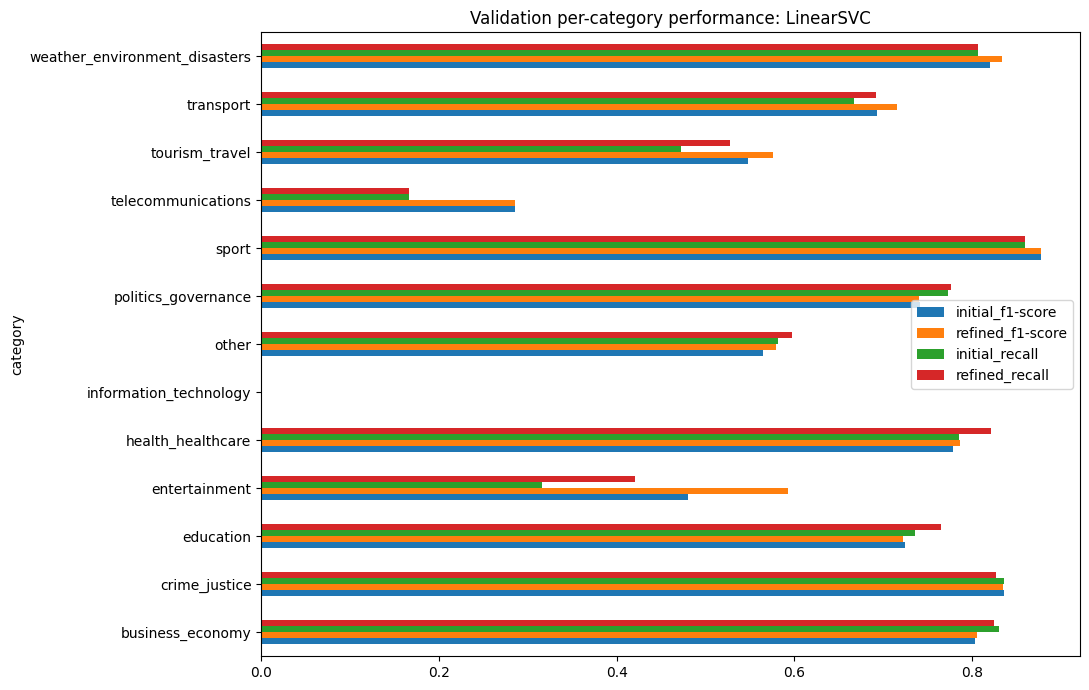

For LinearSVC, the largest numerical F1 increase is entertainment (+0.1126); the smallest change is education (-0.0024). Added-count/F1-change Pearson correlation is -0.291 (undefined if either variable is constant). It is descriptive across 13 categories and cannot establish causation. Zero-support categories have zero computed scores and should not be interpreted as measured failure.

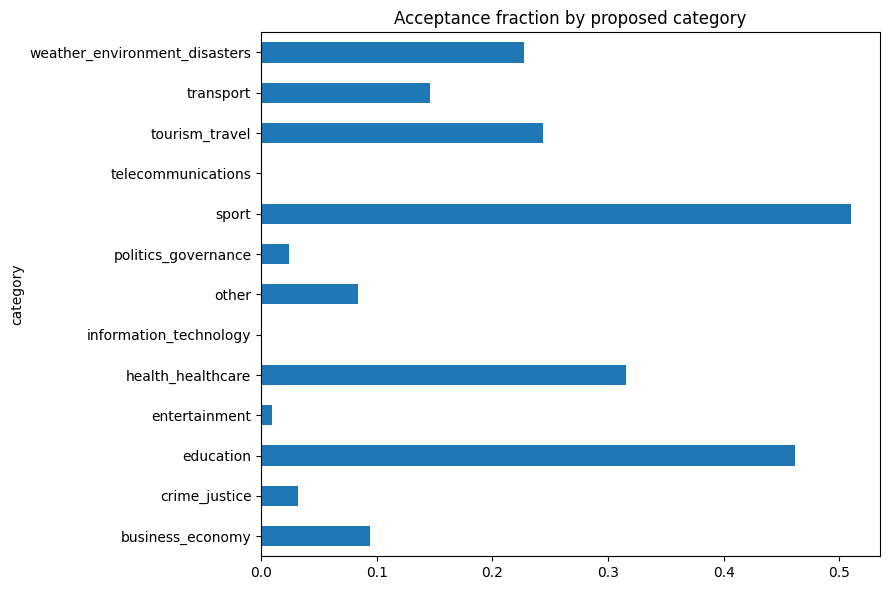

Acceptance rates are computed after caps from 3,041 training candidates. ['information_technology', 'telecommunications'] receive no additions. Sparse seeds restrict each cap; shared model biases may also restrict acceptance, but this plot alone cannot separate those explanations.

In [ ]:
category['acceptance_rate']=category.added/category.eligible_candidate_count.replace(0,np.nan)

category['validation_support']=[initial_report[t]['support'] for t in TOPICS]

table('per_category_model_comparison',category)

category.set_index('category')[['initial_f1-score','refined_f1-score','initial_recall','refined_recall']].plot.barh(figsize=(11,7),title=f'Validation per-category performance: {analysis_model}')

gain=category.sort_values('f1_difference',ascending=False).iloc[0]

loss=category.sort_values('f1_difference').iloc[0]

corr=category.added.corr(category.f1_difference)

figure('per_category_performance',f'For {analysis_model}, the largest numerical F1 increase is {gain.category} ({gain.f1_difference:+.4f}); the smallest change is {loss.category} ({loss.f1_difference:+.4f}). Added-count/F1-change Pearson correlation is {corr:.3f} (undefined if either variable is constant). It is descriptive across 13 categories and cannot establish causation. Zero-support categories have zero computed scores and should not be interpreted as measured failure.')

category.set_index('category').acceptance_rate.plot.barh(figsize=(9,6),title='Acceptance fraction by proposed category')

figure('per_category_acceptance',f'Acceptance rates are computed after caps from {len(pool):,} training candidates. {category.loc[category.added.eq(0),"category"].tolist()} receive no additions. Sparse seeds restrict each cap; shared model biases may also restrict acceptance, but this plot alone cannot separate those explanations.')


## 17. Classification Error Analysis

- Examine validation articles where a classifier's predicted topic differs from the original BART pseudo-label.
- A disagreement can come from a classifier mistake, an incorrect BART label, or an article that reasonably fits multiple topics. Reading individual examples helps distinguish these possibilities.
- Look for recurring patterns by comparing frequently confused topic pairs, disagreement rates for short and long articles, and disagreements across prediction score ranges. These patterns help identify cases for closer review.

### Step 17.1 — Collect Validation Disagreements for Review

- Load the saved validation predictions for each classifier and training setup. Keep rows where the classifier's prediction differs from the BART reference label.
- For each disagreement, record the article ID, description, first 400 characters, word count, BART reference label, model prediction, score, score type, classifier, and training setup.
- Combine the rows into the `classification_errors` table. The same article can appear multiple times if more than one classifier or setup disagrees with BART.
- Create `focus` for the next analysis by keeping only disagreements from the `selected_refined` version of `analysis_model`, which is **LinearSVC** in this run.

In [ ]:
errors=[]

for stage,name in VALIDATION_PREDICTIONS:
    p=OUT/f'validation_{stage}_{name.replace(" ","_")}_predictions.csv'
    records=pd.read_csv(p,dtype={'doc_id':str})
    bad=records.loc[records.predicted_topic.ne(records.prediction)].copy()
    bad['reference_label']=bad.predicted_topic;bad['reference_source']='BART pseudo-label, unverified'
    bad['article_excerpt']=bad.article.str[:400]
    bad['word_count']=bad.article.str.split().str.len()
    errors.append(bad[['doc_id','description','article_excerpt','reference_label','reference_source','prediction','score','score_type','model','stage','word_count']])

error_table=pd.concat(errors,ignore_index=True)

table('classification_errors',error_table)

focus=error_table.loc[error_table.model.eq(analysis_model)&error_table.stage.eq('selected_refined')]


,doc_id,description,article_excerpt,reference_label,reference_source,prediction,score,score_type,model,stage,word_count
0,2023-10-23-dbsjeyarajcom-38880dbe,"Keheliya Rambukwella, Mahinda Amaraweera and D...","Keheliya Rambukwella, Mahinda Amaraweera and D...",politics_governance,"BART pseudo-label, unverified",health_healthcare,0.325018,uncalibrated model probability,Logistic regression,initial,212
1,2023-10-31-dbsjeyarajcom-0092bfd0,Hamas committed war crimes. Israel is committi...,Hamas committed war crimes. Israel is committi...,crime_justice,"BART pseudo-label, unverified",politics_governance,0.413115,uncalibrated model probability,Logistic regression,initial,2218
2,2023-11-09-dbsjeyarajcom-6e7bc767,"Without Taking a Formal Vote, Parliament Unani...","Without Taking a Formal Vote, Parliament Unani...",sport,"BART pseudo-label, unverified",politics_governance,0.726235,uncalibrated model probability,Logistic regression,initial,1170
3,2023-12-02-dbsjeyarajcom-d91b07c4,Gamini “Gamma”Weerakoon: From Reporter to Editor.,Gamini “Gamma”Weerakoon: From Reporter to Edit...,other,"BART pseudo-label, unverified",politics_governance,0.417167,uncalibrated model probability,Logistic regression,initial,2329
4,2023-12-08-dbsjeyarajcom-d930c2e0,“Nadigaiyar Thilagam “( Doyenne of Actresses) ...,“Nadigaiyar Thilagam “( Doyenne of Actresses) ...,entertainment,"BART pseudo-label, unverified",other,0.593002,uncalibrated model probability,Logistic regression,initial,3108
...,...,...,...,...,...,...,...,...,...,...,...
7988,2024-05-04-colombotelegraphcom-baefaa2a,The “Aragalaya“ Of 1848,The “Aragalaya“ Of 1848\nThe “Aragalaya“ Of 18...,politics_governance,"BART pseudo-label, unverified",other,0.691429,uncalibrated model probability,Stacking,weighted_refined,1903
7989,2024-05-05-dailyftlk-14478bfe,How technology is remaking the world of work i...,How technology is remaking the world of work i...,information_technology,"BART pseudo-label, unverified",business_economy,0.875168,uncalibrated model probability,Stacking,weighted_refined,933
7990,2024-05-06-adaderanalk-87dc3a8c,Gammanpila calls for Central Bank governor’s r...,Gammanpila calls for Central Bank governor’s r...,business_economy,"BART pseudo-label, unverified",information_technology,0.659113,uncalibrated model probability,Stacking,weighted_refined,261
7991,2024-05-06-dailyftlk-ad7b8f2b,Govt. kicks off revolutionary move of granting...,Govt. kicks off revolutionary move of granting...,business_economy,"BART pseudo-label, unverified",information_technology,0.328651,uncalibrated model probability,Stacking,weighted_refined,298


### Step 17.2 — Identify Common Topic Confusions

- Group the `selected_refined` LinearSVC disagreements by **BART reference topic → predicted topic**. Count the articles in each pair and sort the pairs from most to least frequent. The direction matters because `crime_justice → politics_governance` and `politics_governance → crime_justice` are different patterns.
- Display the first eight disagreements so individual articles can be reviewed alongside the aggregate counts.
- Read the confusion matrix by row and column. **Rows** are BART reference topics, and **columns** are LinearSVC predictions. Diagonal cells count agreements, while off-diagonal cells count disagreements. The matrix includes all validation articles.
- For example, among articles BART labeled `crime_justice`, LinearSVC also predicted `crime_justice` for **297** and predicted `politics_governance` for **28**. In the reverse direction, **19** articles labeled `politics_governance` by BART were predicted as `crime_justice`.
- The matrix measures agreement with BART. Reviewing the articles helps determine which label better fits the text.

,reference_label,prediction,articles
0,business_economy,politics_governance,37
1,politics_governance,business_economy,30
2,crime_justice,politics_governance,28
3,politics_governance,crime_justice,19
4,crime_justice,business_economy,17
...,...,...,...
67,telecommunications,politics_governance,1
68,transport,weather_environment_disasters,1
69,transport,politics_governance,1
70,weather_environment_disasters,crime_justice,1


,doc_id,description,article_excerpt,reference_label,reference_source,prediction,score,score_type,model,stage,word_count
5180,2023-10-23-dbsjeyarajcom-38880dbe,"Keheliya Rambukwella, Mahinda Amaraweera and D...","Keheliya Rambukwella, Mahinda Amaraweera and D...",politics_governance,"BART pseudo-label, unverified",health_healthcare,-0.034419,uncalibrated decision score,LinearSVC,selected_refined,212
5181,2023-11-09-dbsjeyarajcom-6e7bc767,"Without Taking a Formal Vote, Parliament Unani...","Without Taking a Formal Vote, Parliament Unani...",sport,"BART pseudo-label, unverified",politics_governance,0.470179,uncalibrated decision score,LinearSVC,selected_refined,1170
5182,2023-11-10-dbsjeyarajcom-8d909f16,"Mammal Species with Hedgehog Spines, Anteater ...","Mammal Species with Hedgehog Spines, Anteater ...",other,"BART pseudo-label, unverified",weather_environment_disasters,-0.378136,uncalibrated decision score,LinearSVC,selected_refined,478
5183,2023-12-02-dbsjeyarajcom-d91b07c4,Gamini “Gamma”Weerakoon: From Reporter to Editor.,Gamini “Gamma”Weerakoon: From Reporter to Edit...,other,"BART pseudo-label, unverified",politics_governance,0.128771,uncalibrated decision score,LinearSVC,selected_refined,2329
5184,2023-12-08-dbsjeyarajcom-d930c2e0,“Nadigaiyar Thilagam “( Doyenne of Actresses) ...,“Nadigaiyar Thilagam “( Doyenne of Actresses) ...,entertainment,"BART pseudo-label, unverified",other,0.309528,uncalibrated decision score,LinearSVC,selected_refined,3108
5185,2024-01-05-dailyftlk-e21d4443,"Centre for Cyber Safety and Education, ISC2 Co...","Centre for Cyber Safety and Education, ISC2 Co...",information_technology,"BART pseudo-label, unverified",education,0.897117,uncalibrated decision score,LinearSVC,selected_refined,467
5186,2024-01-06-dailyftlk-4e03483c,"Voet, my foot","Voet, my foot\nVoet, my foot\n\nJohannes Voet ...",crime_justice,"BART pseudo-label, unverified",other,-0.229843,uncalibrated decision score,LinearSVC,selected_refined,951
5187,2024-01-08-dailyftlk-a910b13c,Ranil’s Red Sea adventures,Ranil’s Red Sea adventures\nRanil’s Red Sea ad...,politics_governance,"BART pseudo-label, unverified",crime_justice,-0.274476,uncalibrated decision score,LinearSVC,selected_refined,1518


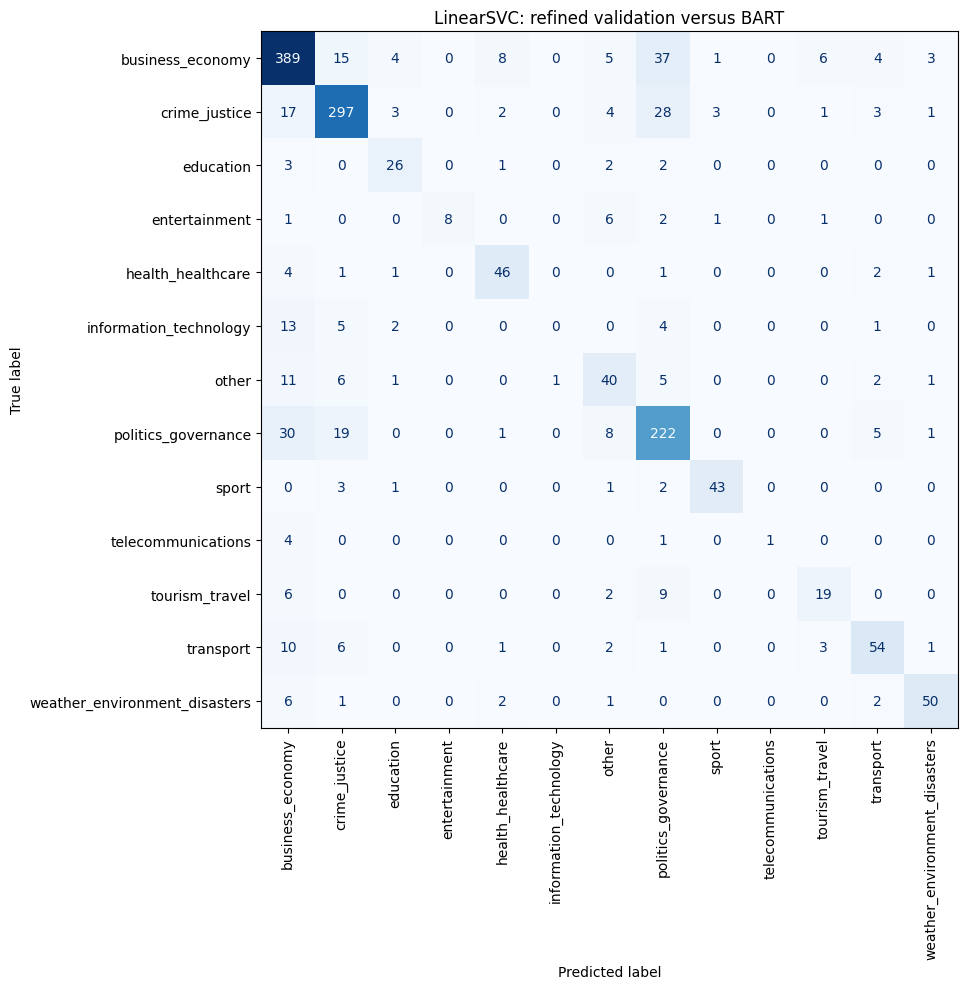

There are 355 BART-reference mismatches for LinearSVC. Most frequent directional confusion: {'reference_label': 'business_economy', 'prediction': 'politics_governance', 'articles': 37}. Median mismatched article length is 292 words. The matrix demonstrates observed label disagreement; overlapping vocabulary, ambiguous stories and incorrect BART labels are plausible causes that require article inspection or human labels to distinguish.

In [ ]:
confusions=focus.groupby(['reference_label','prediction']).size().sort_values(ascending=False).rename('articles').reset_index()

table('common_category_confusions',confusions)

display(focus.head(8))

fig,ax=plt.subplots(figsize=(12,10))

ConfusionMatrixDisplay.from_predictions(validation.predicted_topic,ref_p,labels=TOPICS,xticks_rotation=90,ax=ax,cmap="Blues",colorbar=False)

plt.title(f'{analysis_model}: refined validation versus BART')

most=confusions.iloc[0].to_dict() if len(confusions) else {}

figure('validation_confusion',f'There are {len(focus):,} BART-reference mismatches for {analysis_model}. Most frequent directional confusion: {most}. Median mismatched article length is {focus.word_count.median():.0f} words. The matrix demonstrates observed label disagreement; overlapping vocabulary, ambiguous stories and incorrect BART labels are plausible causes that require article inspection or human labels to distinguish.')


## 18. Model Explainability — Which Terms Influence Topic Predictions?

- **Across articles**, the coefficients of Logistic Regression and LinearSVC show which TF-IDF terms the models associate most strongly with each topic. A positive coefficient means the term pushes the model's score toward that topic when it appears.
- **For a single article**, multiply a term's TF-IDF value by its coefficient to see how much that term contributes to the topic score. If the term is absent, its contribution is zero.
- Publisher names can also have large coefficients. This may indicate that a classifier has learned an association between a news source and a topic. These coefficients describe how the linear classifiers score text. Explaining a stacking prediction requires examining how the ensemble combines its base models' outputs.

### Step 18.1 — Find the Top Terms for Each Topic

- Extract the TF-IDF terms and their coefficients from the `selected_refined` versions of **Logistic Regression** and **LinearSVC**.
- For each classifier and topic, save the **12 terms with the highest coefficients** in `linear_influential_features` and display the top **five**.
- In the preview, Logistic Regression associates `economynext` (**2.624**), `bank` (**1.977**), and `percent` (**1.965**) with `business_economy`. The term `bank` is a topic clue, while `economynext` is a publisher cue. Both can raise the model's score for that topic.

In [ ]:
explanations=[]

for name in ['Logistic regression','LinearSVC']:
    model=BUNDLES['selected_refined']['base'][name]
    clf=model.named_steps['classifier'];terms=model.named_steps['tfidf'].get_feature_names_out()
    for class_idx,coef in enumerate(clf.coef_):
        for j in np.argsort(coef)[-12:][::-1]:
            explanations.append({'model':name,'category':TOPICS[class_idx],'term':terms[j],'coefficient':coef[j]})

table('linear_influential_features',pd.DataFrame(explanations))

display(pd.DataFrame(explanations).groupby(['model','category']).head(5))

prose('Interpreting influential features','Inspect the exported top terms for meaningful topic vocabulary and publisher names or boilerplate. These coefficients describe learned associations; they do not verify an article label. Repeated source-specific terms would motivate a future source-held-out evaluation. No causal claim about particular errors follows from coefficients alone.')


,model,category,term,coefficient
0,Logistic regression,business_economy,economynext,2.624085
1,Logistic regression,business_economy,bank,1.976583
2,Logistic regression,business_economy,percent,1.964977
3,Logistic regression,business_economy,business,1.909074
4,Logistic regression,business_economy,economic,1.853005
...,...,...,...,...
307,LinearSVC,weather_environment_disasters,climate,0.994687
308,LinearSVC,weather_environment_disasters,area,0.983471
309,LinearSVC,weather_environment_disasters,magnitude,0.928978
310,LinearSVC,weather_environment_disasters,pollution,0.917838


,model,category,term,coefficient
0,Logistic regression,business_economy,economynext,2.624085
1,Logistic regression,business_economy,bank,1.976583
2,Logistic regression,business_economy,percent,1.964977
3,Logistic regression,business_economy,business,1.909074
4,Logistic regression,business_economy,economic,1.853005
...,...,...,...,...
300,LinearSVC,weather_environment_disasters,weather,1.295346
301,LinearSVC,weather_environment_disasters,environmental,1.208860
302,LinearSVC,weather_environment_disasters,disaster,1.158811
303,LinearSVC,weather_environment_disasters,plastic,1.151847


### Interpreting influential features

Inspect the exported top terms for meaningful topic vocabulary and publisher names or boilerplate. These coefficients describe learned associations; they do not verify an article label. Repeated source-specific terms would motivate a future source-held-out evaluation. No causal claim about particular errors follows from coefficients alone.

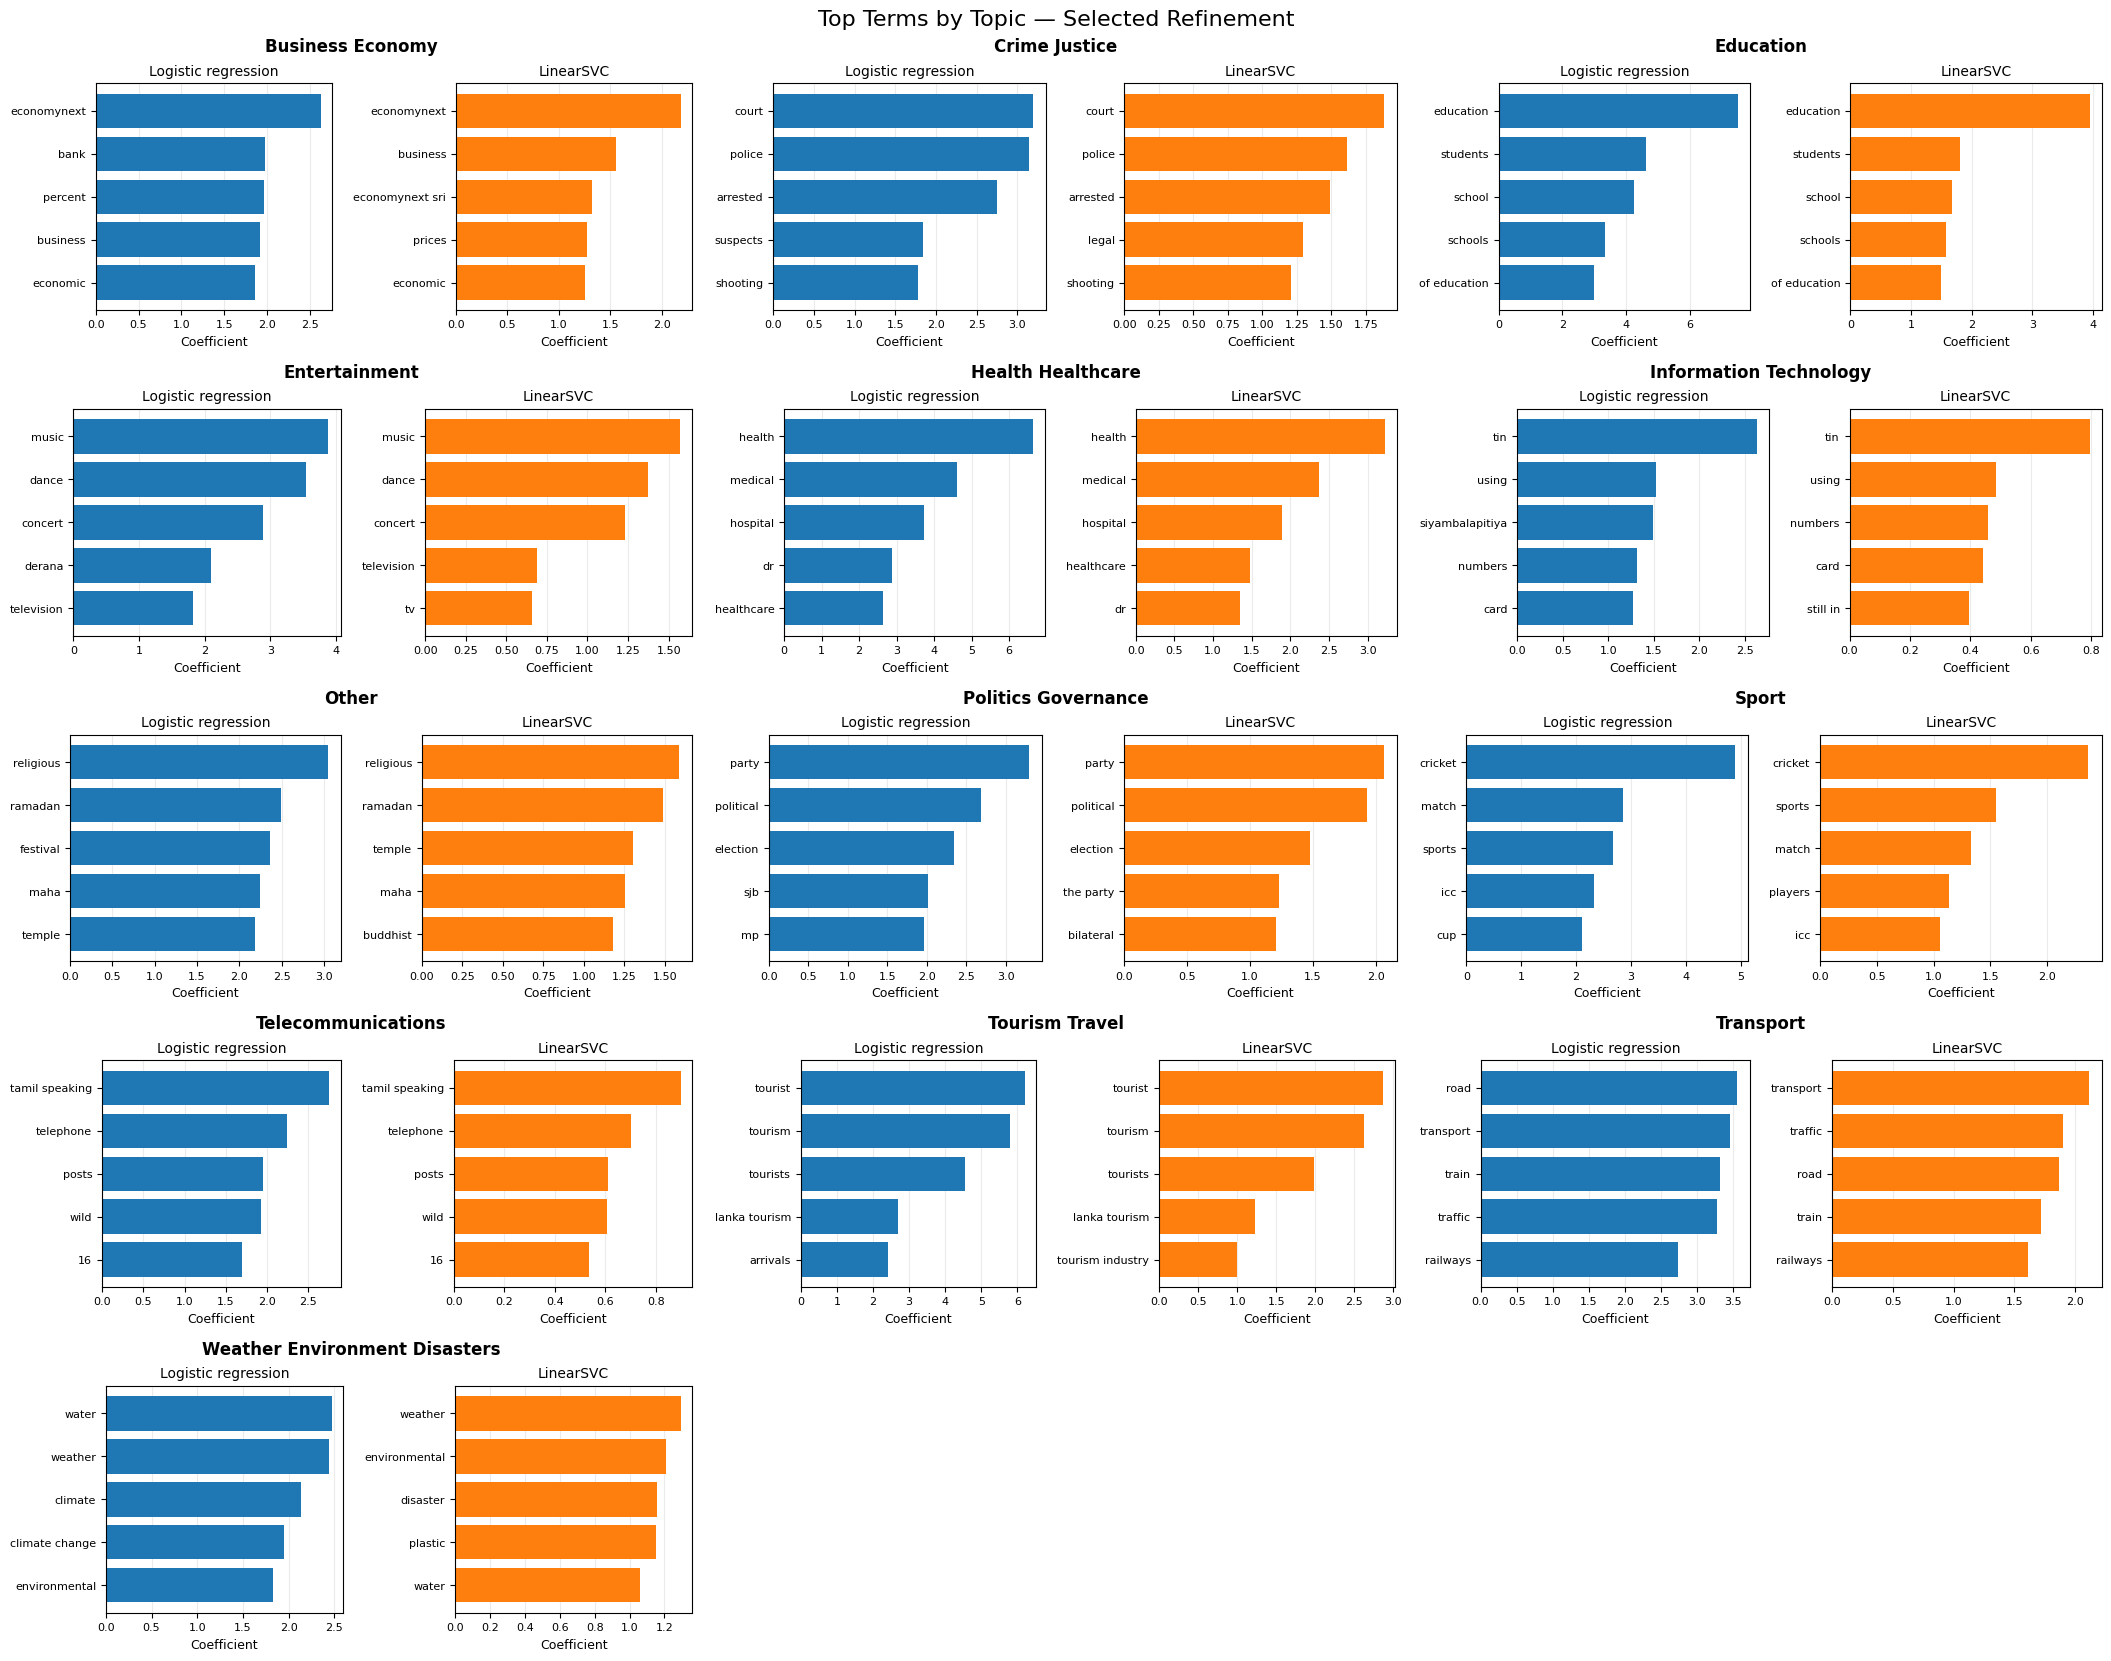

In [ ]:
from math import ceil

feature_df = pd.DataFrame(explanations)
model_styles = [
    ("Logistic regression", "tab:blue"),
    ("LinearSVC", "tab:orange"),
]

ncols = 3
nrows = ceil(len(TOPICS) / ncols)
top_n = 5

fig = plt.figure(figsize=(21, 3.3 * nrows), layout="constrained")
category_grid = fig.add_gridspec(nrows, ncols)

for index, topic in enumerate(TOPICS):
    row, col = divmod(index, ncols)
    topic_features = feature_df.loc[feature_df["category"].eq(topic)]

    category_fig = fig.add_subfigure(category_grid[row, col])
    category_fig.suptitle(topic.replace("_", " ").title(), fontweight="bold")
    axes = category_fig.subplots(1, 2)

    for ax, (model_name, color) in zip(axes, model_styles):
        top_terms = (
            topic_features.loc[
                topic_features["model"].eq(model_name)
                & topic_features["coefficient"].gt(0)
            ]
            .nlargest(top_n, "coefficient")
            .sort_values("coefficient")
        )

        ax.barh(top_terms["term"], top_terms["coefficient"], color=color)
        ax.set_title(model_name, fontsize=10)
        ax.set_xlabel("Coefficient", fontsize=9)
        ax.tick_params(axis="both", labelsize=8)
        ax.grid(axis="x", alpha=0.25)
        ax.set_axisbelow(True)

fig.suptitle("Top Terms by Topic — Selected Refinement", fontsize=16)
plt.show()

## 19. Final Model Selection

- Rank all classifier and training setup combinations by **validation macro F1**, which gives each topic equal weight.
- Break exact ties using **higher weighted F1**, then **shorter fit time**.
- In this run, **LinearSVC trained with `selected_refined`** ranked first with a macro F1 of **0.642161**. The `weighted_refined` version of LinearSVC was nearly tied at **0.642094**.
- Use validation results against BART pseudo-labels to make the selection. Save the decision before running the subsequent test and audit evaluations, and record that earlier notebook test results had already been viewed.

### Step 19.1 — Rank the Results and Prepare the Selection Record

- Sort `comparison` by macro F1, weighted F1, and fit time. Take the first row as `chosen` and store its classifier and training setup in `FINAL_MODEL` and `FINAL_STAGE`.
- Retrieve the fitted model bundle for the winning setup and the training articles used by that setup. For this run, the training set contains **3,156 seed articles and 315 added articles**.
- Prepare a record containing the selected classifier and setup, validation metrics, screening-selected rule, dataset and run identifiers, and software versions.

In [ ]:
ranked=comparison.sort_values(['macro_f1','weighted_f1','fit_seconds'],ascending=[False,False,True]).reset_index(drop=True)

chosen=ranked.iloc[0]

FINAL_STAGE,FINAL_MODEL=chosen.stage,chosen.model

FINAL_BUNDLE=BUNDLES[FINAL_STAGE]

FINAL_ARTICLES=seed if FINAL_STAGE=='initial' else TRAINING_SETS[FINAL_STAGE]

freeze={'dataset_sha256':DATA_HASH,'run_hash':RUN_HASH,'config':CONFIG,'selected_stage':FINAL_STAGE,
    'selected_model':FINAL_MODEL,'validation_metrics':chosen.to_dict(),'selected_rule':BEST_RULE,
    'selection_policy':'validation macro F1, weighted F1 and fit seconds for exact ties',
    'reference':'BART pseudo-labels, not human ground truth','categories':TOPICS,
    'test_development_exposure':'prior notebook test results were already viewed',
    'versions':{'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,'scikit-learn':sklearn.__version__,'xgboost':xgboost.__version__}}

freeze_path=OUT/'frozen_selection.json'


### Step 19.2 — Save or Verify the Frozen Selection

- If `frozen_selection.json` does not exist, write the selection record to that file.
- If it already exists, check that the current classifier and training setup match the saved selection.
- If either differs, stop with an assertion error. This prevents a rerun from silently replacing the recorded decision.

In [ ]:
if freeze_path.exists():
    previous=json.loads(freeze_path.read_text())
    assert (previous['selected_stage'],previous['selected_model'])==(FINAL_STAGE,FINAL_MODEL), 'Selection differs from frozen run; use a new protocol version'
else: freeze_path.write_text(json.dumps(freeze,indent=2,default=str))

artifact={'bundle':FINAL_BUNDLE if FINAL_MODEL=='Stacking' else None,
          'pipeline':None if FINAL_MODEL=='Stacking' else FINAL_BUNDLE['base'][FINAL_MODEL],
          'model_name':FINAL_MODEL,'topics':TOPICS,'stage':FINAL_STAGE,'selection':freeze,
          'input_policy':'headline + newline + full body, Unicode normalization inside TF-IDF'}

joblib.dump(artifact,OUT/'final_classifier.joblib',compress=3)

(OUT/'model_requirements.txt').write_text('\n'.join(f'{k}=={v}' for k,v in freeze['versions'].items() if k!='python'))

runner_up=ranked.iloc[1]

prose('Frozen classifier',f'Selected **{FINAL_MODEL} ({FINAL_STAGE})**, validation macro F1 {chosen.macro_f1:.4f}, weighted F1 {chosen.weighted_f1:.4f}, macro recall {chosen.recall:.4f}. The next configuration is {runner_up.model} ({runner_up.stage}), macro F1 {runner_up.macro_f1:.4f}; the gap is {chosen.macro_f1-runner_up.macro_f1:.4f}. A small gap is not evidence of meaningful superiority. Selection is fixed before test and human audit evaluation.')


### Frozen classifier

Selected **LinearSVC (selected_refined)**, validation macro F1 0.6422, weighted F1 0.7637, macro recall 0.6219. The next configuration is LinearSVC (weighted_refined), macro F1 0.6421; the gap is 0.0001. A small gap is not evidence of meaningful superiority. Selection is fixed before test and human audit evaluation.

## 20. Evaluate the Frozen Model on the Test Split

- Evaluate the classifier and training setup selected using validation macro F1. In this run, the frozen choice was **LinearSVC trained with `selected_refined`**.
- Keep the model choice fixed throughout test evaluation. Use the test predictions to measure agreement with the BART pseudo-labels on held-out articles.
- Earlier test results had already been viewed during project development. This evaluation uses a new split from the same dataset, so performance on a genuinely external dataset remains unknown.

### Step 20.1 — Define How to Score Articles With the Saved Model

- For **LinearSVC**, use `decision_function()` to obtain a score for each class. These scores express the model's preference among topics and can be used to rank them.
- For **stacking**, retrieve the ensemble's scores from the saved model bundle. For the other classifiers, use `predict_proba()` to obtain class probabilities.

In [ ]:
def artifact_scores(artifact,texts):
    if artifact['model_name']=='Stacking':return outputs(artifact['bundle'],texts)['Stacking']
    m=artifact['pipeline']
    return m.decision_function(texts) if artifact['model_name']=='LinearSVC' else m.predict_proba(texts)


### Step 20.2 — Generate or Reload the Final Test Predictions

- If `final_test_predictions.csv` already exists, reload it and check that the article IDs match the current test split in the same order. Also verify that every row matches the frozen classifier and training setup.
- Otherwise, score the test articles with the saved model and record the predicted topic, top score, and margin between the top two scores.
- Save those results alongside the article ID, description, original BART topic, duplicate group, classifier, and training setup. The saved predictions can then be used to calculate the final test metrics.

In [ ]:
test_path=OUT/'final_test_predictions.csv'

if test_path.exists():
    test_predictions=pd.read_csv(test_path,dtype={'doc_id':str})
    assert test_predictions.doc_id.tolist()==test.doc_id.tolist()
    assert test_predictions.model.eq(FINAL_MODEL).all() and test_predictions.stage.eq(FINAL_STAGE).all()
else:
    test_scores=artifact_scores(artifact,test.article)
    p,s,m=summarize_scores(test_scores,FINAL_MODEL)
    test_predictions=test[['doc_id','description','predicted_topic','duplicate_group']].copy()
    test_predictions['prediction']=p;test_predictions['score']=s;test_predictions['margin']=m
    test_predictions['model']=FINAL_MODEL;test_predictions['stage']=FINAL_STAGE
    test_predictions.to_csv(test_path,index=False)


### Step 20.3 — Report Final Test Metrics and Plot the Confusion Matrix

- Compare the frozen LinearSVC model's predictions with the BART pseudo-labels on the test split. Save the overall metrics in `final_test_metrics` and the per-topic precision, recall, F1, and article counts in `final_test_per_category`.
- In the confusion matrix, rows show BART's topics and columns show LinearSVC's predictions. Diagonal cells count agreements. Off-diagonal cells show which topics the model predicted when it disagreed with BART.
- For example, LinearSVC agreed with BART on **510** articles labeled `business_economy` and predicted `politics_governance` for **54** articles from that same reference category.
- These results describe agreement with BART on the held-out test articles. Human-reviewed labels provide a separate reference for assessing topic correctness.

,model,stage,n,reference,accuracy,macro_f1,weighted_f1,precision,recall
0,LinearSVC,selected_refined,1941,BART pseudo-label,0.771252,0.601913,0.761761,0.665167,0.588653


,category,precision,recall,f1-score,support
0,business_economy,0.814696,0.825243,0.819936,618.000000
1,crime_justice,0.816229,0.814286,0.815256,420.000000
2,education,0.682540,0.781818,0.728814,55.000000
3,entertainment,1.000000,0.181818,0.307692,11.000000
4,health_healthcare,0.765432,0.826667,0.794872,75.000000
5,information_technology,0.000000,0.000000,0.000000,30.000000
6,other,0.615385,0.454545,0.522876,88.000000
7,politics_governance,0.680095,0.827089,0.746424,347.000000
8,sport,0.945455,0.945455,0.945455,55.000000
9,telecommunications,0.000000,0.000000,0.000000,6.000000


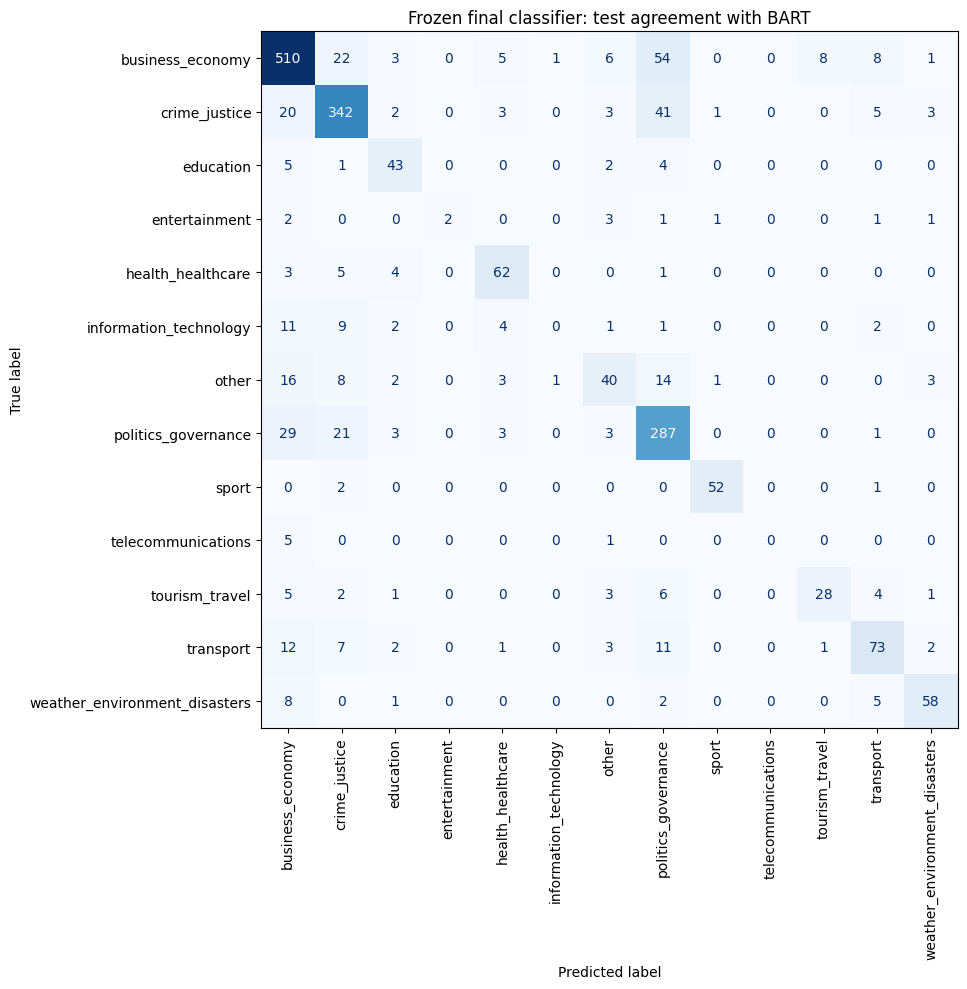

The frozen LinearSVC achieves test BART agreement 0.7713, macro F1 0.6019 and weighted F1 0.7618 across 1,941 articles. These scores estimate imitation of BART references on the fixed split; human-label accuracy is pending separately.

In [ ]:
test_metrics=metrics(test_predictions.predicted_topic,test_predictions.prediction)

table('final_test_metrics',pd.DataFrame([dict(model=FINAL_MODEL,stage=FINAL_STAGE,n=len(test),reference='BART pseudo-label',**test_metrics)]))

table('final_test_per_category',pd.DataFrame(classification_report(test_predictions.predicted_topic,test_predictions.prediction,labels=TOPICS,output_dict=True,zero_division=0)).T.reset_index(names='category'))

fig,ax=plt.subplots(figsize=(12,10))

ConfusionMatrixDisplay.from_predictions(test_predictions.predicted_topic,test_predictions.prediction,labels=TOPICS,xticks_rotation=90,ax=ax,cmap="Blues",colorbar=False)

plt.title('Frozen final classifier: test agreement with BART')

figure('final_test_confusion',f'The frozen {FINAL_MODEL} achieves test BART agreement {test_metrics["accuracy"]:.4f}, macro F1 {test_metrics["macro_f1"]:.4f} and weighted F1 {test_metrics["weighted_f1"]:.4f} across {len(test):,} articles. These scores estimate imitation of BART references on the fixed split; human-label accuracy is pending separately.')


## 21. Predict the Category of a New News Article
Load the saved final model without retraining. Enter a headline, body or a CSV with `article_title`/`article_text` (or `description`/`text`). The returned score is explicitly typed. Probability and decision-margin abstention thresholds are configurable heuristics and have not been tuned using the audit. Alternative labels and scores are available; uncertain predictions are flagged for review.

### Step 21.1 — Define Single-Article and Batch Prediction

- Define `predict_news()` to load the trained pipeline from `final_classifier.joblib` and use it for prediction.
- For a single article, pass a headline, article body, or both. For batch prediction, pass a CSV with at least one supported column: `article_title` or `description` for the headline, and `article_text` or `text` for the body.
- For LinearSVC, flag predictions for review when the top two decision scores are too close. The default minimum gap is **0.25**.
- For models that return probabilities, the default review cutoffs are a top probability of **0.60** and a top-two probability gap of **0.15**. These cutoffs are configurable heuristics and were set without tuning on the audit.

In [ ]:
def predict_news(headline='',body='',csv_path=None,probability_threshold=.60,probability_margin=.15,decision_margin=.25,output_path=None):
    saved=joblib.load(OUT/'final_classifier.joblib')  # Only load your own trusted artifact.
    if csv_path is not None:
        batch=pd.read_csv(csv_path,keep_default_na=False)
        title_col='article_title' if 'article_title' in batch else 'description'
        text_col='article_text' if 'article_text' in batch else 'text'
        assert title_col in batch or text_col in batch, 'CSV needs a headline or text column'
        titles=batch[title_col].astype(str) if title_col in batch else pd.Series('',index=batch.index)
        bodies=batch[text_col].astype(str) if text_col in batch else pd.Series('',index=batch.index)
    else:
        batch=pd.DataFrame({'article_title':[headline],'article_text':[body]})
        titles=batch.article_title.astype(str);bodies=batch.article_text.astype(str)
    texts=titles+'\n'+bodies
    assert texts.str.strip().ne('').all(), 'Empty article input'
    scores=artifact_scores(saved,texts)
    p,score,margin=summarize_scores(scores,saved['model_name'])
    is_decision=saved['model_name']=='LinearSVC'
    batch['predicted_category']=p;batch['score']=score;batch['margin']=margin
    batch['score_type']='uncalibrated decision score' if is_decision else 'uncalibrated model probability'
    batch['needs_review']=margin<decision_margin if is_decision else ((score<probability_threshold)|(margin<probability_margin))
    order=np.argsort(scores,axis=1)[:,::-1]
    for rank in [1,2,3]:
        batch[f'alternative_{rank}']=[saved['topics'][j] for j in order[:,rank-1]]
        batch[f'alternative_{rank}_score']=scores[np.arange(len(batch)),order[:,rank-1]]
    if csv_path is not None:batch.to_csv(output_path or OUT/'new_article_predictions.csv',index=False,encoding='utf-8-sig')
    return batch


### Step 21.2 — Explain Which Terms Influenced an Article’s Prediction

- Load the saved classifier and combine the headline and body into one text input. This explanation is available for **LinearSVC** and **Logistic Regression**.
- Predict the article’s topic and convert its text into TF-IDF features using the fitted vectorizer.
- For each term in the article, multiply its **TF-IDF value** by its **learned coefficient for the predicted topic**. Positive contributions raise that topic’s score, and negative contributions lower it.
- Return the **12 highest contributions** by default. These values explain how terms in this particular article affect the predicted topic’s score.

In [ ]:
def explain_new_article(headline,body,top_n=12):
    saved=joblib.load(OUT/'final_classifier.joblib')
    if saved['model_name'] not in ['LinearSVC','Logistic regression']:
        return 'Local linear feature contributions are available only when the frozen classifier is LR or LinearSVC; see global base-model term tables otherwise.'
    model=saved['pipeline'];text=headline+'\n'+body
    x=model.named_steps['tfidf'].transform([text]);pred=int(model.predict([text])[0])
    contrib=x.multiply(model.named_steps['classifier'].coef_[pred]).tocoo()
    names=model.named_steps['tfidf'].get_feature_names_out()
    frame=pd.DataFrame({'term':names[contrib.col],'contribution':contrib.data})
    return frame.sort_values('contribution',ascending=False).head(top_n)


### Step 21.3 — Run an Example Prediction on a Test Article

- Pass the headline and body of the first test article to `predict_news()`. The saved LinearSVC model predicts **`politics_governance`**, with **`crime_justice`** as the runner-up.
- The top decision score is **−0.0594** and the runner-up score is **−0.5230**. Both scores are negative, and `politics_governance` wins because its score is higher. LinearSVC decision scores are uncalibrated.
- The gap between the two scores is **0.4636**, which exceeds the default review threshold of **0.25**. Therefore, `needs_review` is `False`.
- The output’s ranked list includes the winning topic in `alternative_1`. The first different topic is in `alternative_2`.

In [ ]:
display(predict_news(headline=test.description.iloc[0],body=test.text.iloc[0]))


,article_title,article_text,predicted_category,score,margin,score_type,needs_review,alternative_1,alternative_1_score,alternative_2,alternative_2_score,alternative_3,alternative_3_score
0,No Moves on to Abolish the Executive Presiden...,No Moves on to Abolish the Executive Presiden...,politics_governance,-0.059428,0.463619,uncalibrated decision score,False,politics_governance,-0.059428,crime_justice,-0.523047,health_healthcare,-0.909613


## 22. Evaluate Predictions Against Human Audit Labels

- Use human-assigned topics as the reference to compare four sets of predictions on the same audit articles: **BART**, the **initial stacking model**, the **screening-selected refined stacking model**, and the **frozen final classifier**.

### Step 22.1 — Build the Audit Prediction Key

In [ ]:
key = audit[['doc_id', 'duplicate_group', 'predicted_topic', 'classification_score', 'score_margin', 'audit_stratum', 'inclusion_probability', 'sampling_weight']].rename(columns={'predicted_topic': 'bart_label', 'classification_score': 'bart_confidence', 'score_margin': 'bart_margin'}).copy()

for prefix, bundle in [('initial_ensemble', initial), ('refined_ensemble', BUNDLES['selected_refined'])]:
    s = outputs(bundle, audit.article)['Stacking']
    p, score, margin = summarize_scores(s, 'Stacking')
    key[prefix + '_prediction'] = p
    key[prefix + '_confidence'] = score
    key[prefix + '_margin'] = margin

p, score, margin = summarize_scores(artifact_scores(artifact, audit.article), FINAL_MODEL)

key['final_prediction'] = p

key['final_score'] = score

key['final_margin'] = margin

key['final_model'] = FINAL_MODEL


### Step 22.2 — Save the Audit Prediction Key

- Record the final model’s training setup and the refinement rule selected during screening.
- Label the final model’s score type. For LinearSVC, it is an **uncalibrated decision score**. For classifiers that use `predict_proba()`, it is an **uncalibrated model probability**.
- Export the key to `human_audit_answer_key.csv` and keep it separate from the blinded file used by reviewers.

In [ ]:
key['final_stage'] = FINAL_STAGE

key['model_score_type'] = 'uncalibrated decision score' if FINAL_MODEL == 'LinearSVC' else 'uncalibrated model probability'

key['refined_rule'] = json.dumps(BEST_RULE, sort_keys=True)

key.to_csv(OUT / 'human_audit_answer_key.csv', index=False, encoding='utf-8-sig')


### Step 22.3 — Validate and Prepare the Human Audit Labels

In [ ]:
def prepare_human_audit():
    human = pd.read_csv(audit_path, dtype={'doc_id': str}, keep_default_na=False)
    assert human.doc_id.is_unique and set(human.doc_id) == set(key.doc_id), 'Invalid audit IDs'
    human['human_label'] = human.human_label.str.strip()
    invalid = set(human.human_label) - set(TOPICS) - {''}
    assert not invalid, f'Invalid human labels: {invalid}'
    completed = human.human_label.ne('').sum()
    if completed < 300:
        status = f'Human audit pending: {completed}/300 valid labels completed. No human accuracy, correction counts or confidence calibration conclusions are available.'
        prose('Human audit status', status)
        return (None, status)
    joined = key.merge(human[['doc_id', 'human_label', 'audit_notes']], on='doc_id', validate='one_to_one')
    rows = []
    ci_rows = []
    confidence_rows = []
    rng = np.random.default_rng(SEED)
    strata_indices = [g.index.to_numpy() for _, g in joined.groupby('audit_stratum')]
    return (joined, rows, ci_rows, confidence_rows, rng, strata_indices)


### Step 22.4 — Calculate Performance Against Human Audit Labels

- Compare **BART**, the **initial stacking model**, the **refined stacking model**, and the **frozen final classifier** against the same 300 human-labeled articles.

In [ ]:
def collect_human_audit_metrics(
    joined, rows, ci_rows, confidence_rows, rng, strata_indices,
    only_model=None,
):
    models = [
        ("BART", "bart_label", "bart_confidence"),
        ("Initial ensemble", "initial_ensemble_prediction", "initial_ensemble_confidence"),
        ("Refined ensemble", "refined_ensemble_prediction", "refined_ensemble_confidence"),
        ("Final classifier", "final_prediction", "final_score"),
    ]

    if only_model is not None and only_model not in {name for name, _, _ in models}:
        raise ValueError(f"Unknown audit model: {only_model}")

    for name, prediction_col, score_col in models:
        if only_model is not None and name != only_model:
            continue

        human_labels = joined["human_label"]
        predictions = joined[prediction_col]
        output_name = name.replace(" ", "_")

        for weighting in ["unweighted audit", "weighted group population"]:
            weights = (
                None if weighting == "unweighted audit" else joined["sampling_weight"]
            )

            rows.append({
                "model": name,
                "weighting": weighting,
                **metrics(human_labels, predictions, weights),
            })

            bootstrap = []
            for _ in range(500):
                indices = np.concatenate([
                    rng.choice(indices, size=len(indices), replace=True)
                    for indices in strata_indices
                ])
                sample = joined.iloc[indices]
                sample_weights = None if weights is None else sample["sampling_weight"]

                bootstrap.append([
                    accuracy_score(
                        sample["human_label"],
                        sample[prediction_col],
                        sample_weight=sample_weights,
                    ),
                    f1_score(
                        sample["human_label"],
                        sample[prediction_col],
                        labels=TOPICS,
                        average="macro",
                        zero_division=0,
                        sample_weight=sample_weights,
                    ),
                ])

            lower, upper = np.quantile(bootstrap, [0.025, 0.975], axis=0)
            ci_rows.append({
                "model": name,
                "weighting": weighting,
                "accuracy_low": lower[0],
                "accuracy_high": upper[0],
                "macro_f1_low": lower[1],
                "macro_f1_high": upper[1],
            })

        report = pd.DataFrame(
            classification_report(
                human_labels,
                predictions,
                labels=TOPICS,
                output_dict=True,
                zero_division=0,
            )
        ).T.reset_index(names="category")
        table(f"audit_report_{output_name}", report)

        disagreements = joined.loc[human_labels.ne(predictions)].copy()
        disagreements["reference_source"] = "independent human audit"
        disagreements["prediction"] = disagreements[prediction_col]
        disagreements["model"] = name
        table(f"audit_errors_{output_name}", disagreements)

        fig, ax = plt.subplots(figsize=(12, 10))
        ConfusionMatrixDisplay.from_predictions(
            human_labels,
            predictions,
            labels=TOPICS,
            xticks_rotation=90,
            ax=ax,
            cmap="Blues",
            colorbar=False,
        )
        ax.set_title(f"{name} versus human labels")
        figure(
            f"audit_confusion_{output_name}",
            f"{name} disagrees with {len(disagreements)} of {len(joined)} human labels. "
            "The matrix shows raw counts from the audit sample. "
            "The inverse-probability estimates describe the population of duplicate groups.",
        )

        if name == "Final classifier" and FINAL_MODEL == "LinearSVC":
            score_groups = pd.qcut(joined[score_col], q=3, duplicates="drop")
        else:
            score_groups = pd.cut(
                joined[score_col],
                [-np.inf, 0.7, 0.9, np.inf],
                labels=["≤ 0.70", "> 0.70 to ≤ 0.90", "> 0.90"],
            )

        for level, group in joined.groupby(score_groups, observed=True):
            confidence_rows.append({
                "model": name,
                "score_group": str(level),
                "n": len(group),
                "human_accuracy": accuracy_score(
                    group["human_label"], group[prediction_col]
                ),
            })

    return joined, rows, ci_rows, confidence_rows

### Step 22.5 — Define finish human audit

This reusable function is defined here; it runs only when called by a later step. Its inputs and returned values connect this step to the next operation.


In [ ]:
def finish_human_audit(joined, rows, ci_rows, confidence_rows):
    table('human_audit_metrics', pd.DataFrame(rows))
    table('human_audit_bootstrap_intervals', pd.DataFrame(ci_rows))
    confidence = pd.DataFrame(confidence_rows)
    table('human_audit_confidence_groups', confidence)
    confidence.pivot(index='score_group', columns='model', values='human_accuracy').plot.bar(figsize=(10, 4), ylim=(0, 1), title='Observed audit correctness by score group')
    figure('audit_confidence_correctness', 'Correctness is computed from the 300 human labels in each score group. Scores are not calibrated probabilities; LinearSVC uses within-model score quantiles. Small groups have substantial uncertainty, and the balanced audit differs from the source population.')
    bart_ok = joined.bart_label.eq(joined.human_label)
    refined_ok = joined.refined_ensemble_prediction.eq(joined.human_label)
    corrections = int((~bart_ok & refined_ok).sum())
    introduced = int((bart_ok & ~refined_ok).sum())
    table('audit_refinement_changes', pd.DataFrame([{'corrected_BART_errors': corrections, 'introduced_errors_vs_correct_BART': introduced}]))
    joined['refinement_outcome'] = np.select([~bart_ok & refined_ok, bart_ok & ~refined_ok], ['corrected_BART_error', 'introduced_error'], default='other')
    table('human_audit_joined_predictions', joined)
    unweighted = pd.DataFrame(rows).query("weighting == 'unweighted audit'")
    winner = unweighted.sort_values('macro_f1', ascending=False).iloc[0]
    status = f'Audit completed: corrected {corrections} BART errors and introduced {introduced} errors relative to correct BART labels. Highest observed unweighted audit macro F1: {winner.model}, {winner.macro_f1:.4f}. The frozen selection remains {FINAL_MODEL} ({FINAL_STAGE}); the audit is not used for selection. Intervals are stratified bootstrap estimates, with limitations for tiny strata and one annotator.'
    prose('Human audit status', status)
    return (pd.DataFrame(rows), status)


### Step 22.6 — Define the Human Audit Evaluation Workflow

- Call `prepare_human_audit()` to validate the audit file and check whether all **300** labels are complete.
- If labeling is incomplete, return the completion status and skip metric calculation.
- If labeling is complete, calculate the audit metrics, generate the reports, and return the metrics table and final status message.

In [ ]:
def audit_evaluate():
    prepared = prepare_human_audit()
    if len(prepared) == 2:
        return prepared
    collected = collect_human_audit_metrics(*prepared)
    return finish_human_audit(*collected)


### Step 22.7 — Run the Human Audit and Save the Results

- Call `audit_evaluate()` to compare BART, the initial stacking model, the refined stacking model, and the frozen final classifier against the human labels.

In [ ]:
# Prepare the audit; keep detailed per-model displays out of the notebook.
from IPython.utils.capture import capture_output
prepared_audit = prepare_human_audit()
audit_ready = len(prepared_audit) != 2
audit_by_model = {}
if audit_ready:
    audit_joined, _, _, _, audit_rng, audit_strata = prepared_audit
    AUDIT_RESULTS, AUDIT_STATUS = None, "Audit prepared. Run the model cells."
else:
    AUDIT_RESULTS, AUDIT_STATUS = prepared_audit

def run_audit_model(name):
    if audit_ready:
        with capture_output():
            audit_by_model[name] = collect_human_audit_metrics(
                audit_joined, [], [], [], audit_rng, audit_strata,
                only_model=name)
        plt.close('all')


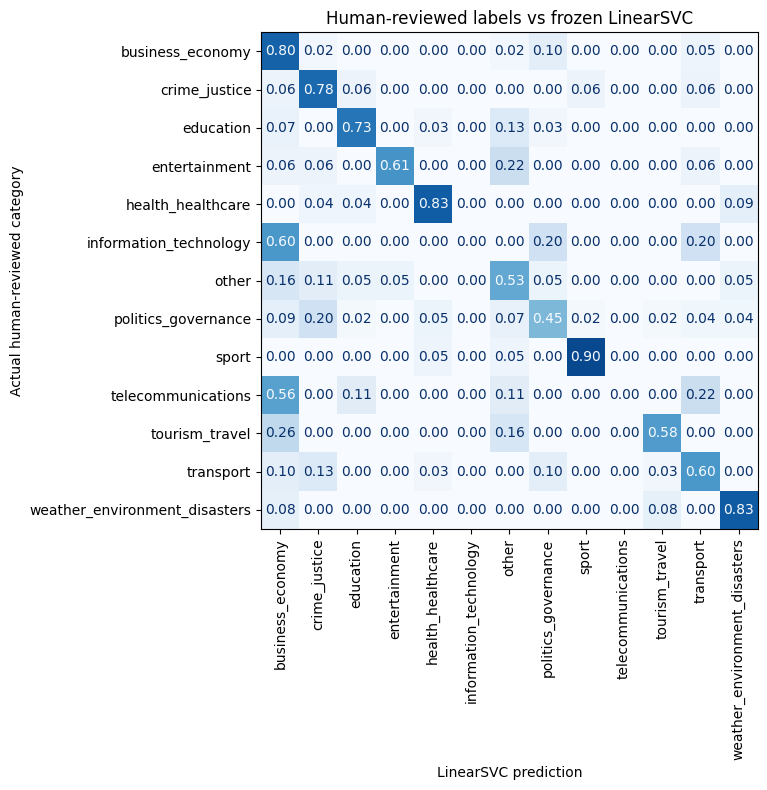

Row-normalized recall against 300 human-reviewed labels. Diagonal cells show category recall; small category samples limit certainty.

In [ ]:
# Human-reviewed labels vs frozen LinearSVC
if audit_ready:
    fig, ax = plt.subplots(figsize=(10, 8))
    heatmap = ConfusionMatrixDisplay.from_predictions(
        audit_joined["human_label"], audit_joined["final_prediction"],
        labels=TOPICS, normalize='true', xticks_rotation=90,
        ax=ax, cmap='Blues', values_format='.2f', colorbar=False)
    heatmap.im_.set_clim(0, 1)
    ax.set(title="Human-reviewed labels vs frozen LinearSVC", ylabel="Actual human-reviewed category",
           xlabel="LinearSVC prediction")
    figure("audit_human_vs_frozen_svc", "Row-normalized recall against 300 human-reviewed labels. Diagonal cells show category recall; small category samples limit certainty.")
else:
    print(AUDIT_STATUS)


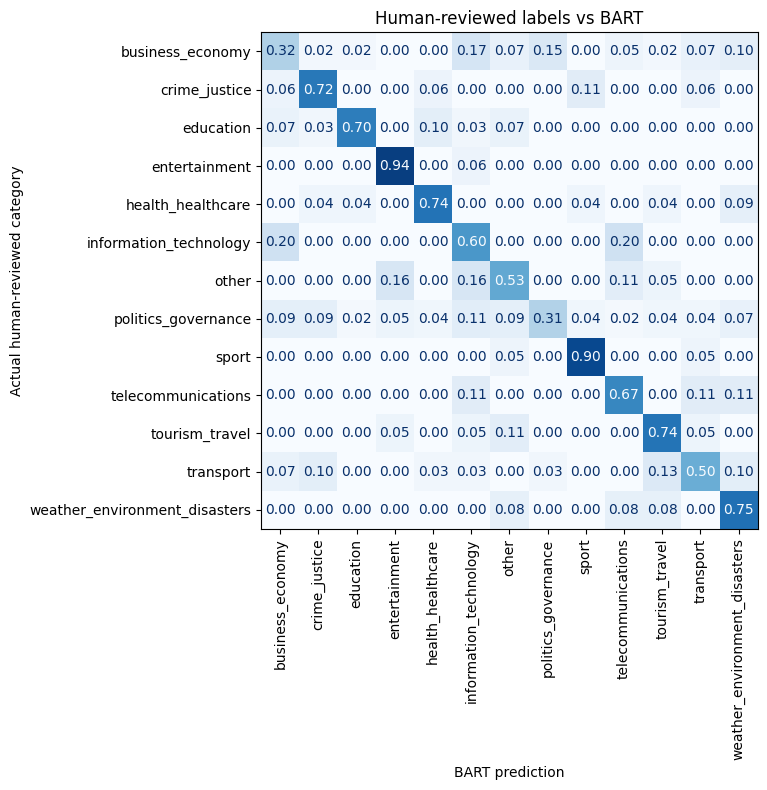

BART evaluated against the same 300 reviewed labels. Diagonal cells show category recall.

In [ ]:
# Human-reviewed labels vs BART
if audit_ready:
    fig, ax = plt.subplots(figsize=(10, 8))
    heatmap = ConfusionMatrixDisplay.from_predictions(
        audit_joined["human_label"], audit_joined["bart_label"],
        labels=TOPICS, normalize='true', xticks_rotation=90,
        ax=ax, cmap='Blues', values_format='.2f', colorbar=False)
    heatmap.im_.set_clim(0, 1)
    ax.set(title="Human-reviewed labels vs BART", ylabel="Actual human-reviewed category",
           xlabel="BART prediction")
    figure("audit_human_vs_bart", "BART evaluated against the same 300 reviewed labels. Diagonal cells show category recall.")
else:
    print(AUDIT_STATUS)


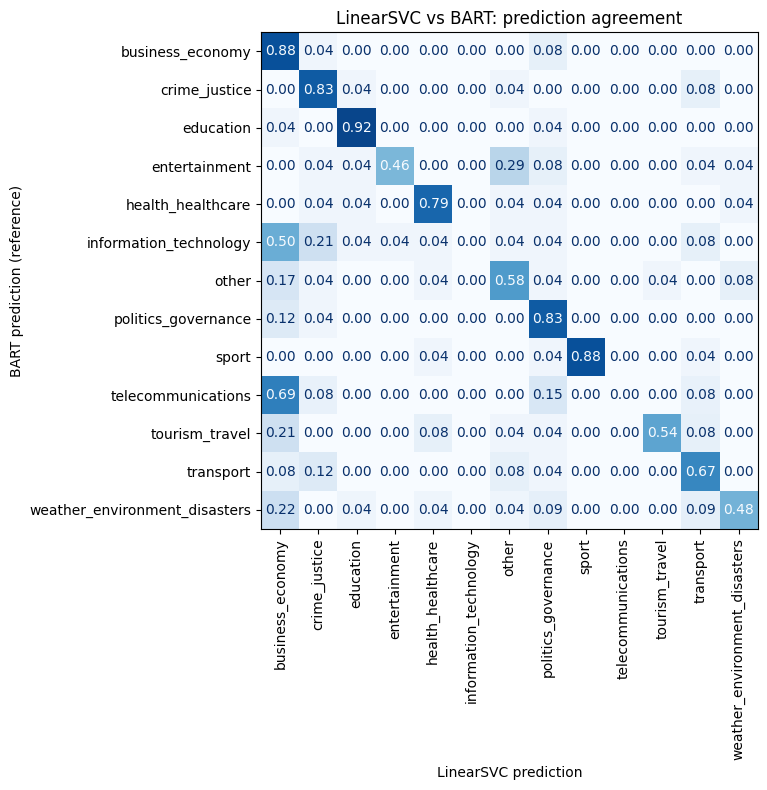

Same 300 audit articles. Rows are BART predictions, columns are frozen LinearSVC predictions. Diagonal cells show agreement with BART, not independently verified accuracy.

In [ ]:
# LinearSVC vs BART: prediction agreement
if audit_ready:
    fig, ax = plt.subplots(figsize=(10, 8))
    heatmap = ConfusionMatrixDisplay.from_predictions(
        audit_joined["bart_label"], audit_joined["final_prediction"],
        labels=TOPICS, normalize='true', xticks_rotation=90,
        ax=ax, cmap='Blues', values_format='.2f', colorbar=False)
    heatmap.im_.set_clim(0, 1)
    ax.set(title="LinearSVC vs BART: prediction agreement", ylabel="BART prediction (reference)",
           xlabel="LinearSVC prediction")
    figure("audit_svc_vs_bart", "Same 300 audit articles. Rows are BART predictions, columns are frozen LinearSVC predictions. Diagonal cells show agreement with BART, not independently verified accuracy.")
else:
    print(AUDIT_STATUS)
